# EN4554 Assignment 2: Convolutional Neural Networks

**Name:** _Jayaweera M.V.L.M_
**Index number:** _220285X_
**GitHub:** [CNN-with-CIFAR10](https://github.com/LahiruMJ11/CNN-with-CIFAR10)

## Setup: CIFAR-10 data pipeline

CIFAR-10 contains 60,000 RGB images of size $32\times32$ in 10 classes: 50,000 standard training images and 10,000 standard test images. The standard training portion is divided into 45,000 training images and 5,000 validation images. The validation partition is used for model and hyperparameter decisions, while the standard test partition is reserved for the single final evaluation in Task 4.

To prevent data leakage, the per-channel mean and population standard deviation are calculated from only the 45,000-image training partition. If $x_{nchw}$ is a pixel scaled to $[0,1]$, the channel statistics are

$$\mu_c=\frac{1}{NHW}\sum_{n,h,w}x_{nchw},\qquad \sigma_c=\sqrt{\frac{1}{NHW}\sum_{n,h,w}x_{nchw}^2-\mu_c^2}.$$

Every training and validation image is then normalized using $\hat{x}_c=(x_c-\mu_c)/\sigma_c$. Since Fixed seeds are using the split and data-loading order repeatable.

In [1]:
import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, Subset
from torchvision import transforms
from torchvision.datasets import CIFAR10

SEED = 42
DATA_ROOT = Path("./data")
TRAIN_SIZE = 45_000
VAL_SIZE = 5_000
BATCH_SIZE = 128

def seed_everything(seed: int = SEED) -> None:
    """Seed Python, NumPy, and PyTorch and request deterministic behavior."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True

def select_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

seed_everything()
device = select_device()
print(f"PyTorch version: {torch.__version__}")
print(f"Selected device: {device}")

PyTorch version: 2.14.1
Selected device: mps


The device-selection order is CUDA (including a Colab T4), Apple MPS, and finally CPU. For this assignment I used Apple MPS.

In [2]:
# download=True downloads on a fresh Colab runtime and reuses the verified local archive here.
raw_dataset = CIFAR10(
    root=DATA_ROOT,
    train=True,
    download=True,
    transform=transforms.ToTensor(),
)

assert len(raw_dataset) == TRAIN_SIZE + VAL_SIZE
split_generator = torch.Generator().manual_seed(SEED)
permutation = torch.randperm(len(raw_dataset), generator=split_generator).tolist()
train_indices = permutation[:TRAIN_SIZE]
val_indices = permutation[TRAIN_SIZE:]

assert len(train_indices) == TRAIN_SIZE
assert len(val_indices) == VAL_SIZE
assert set(train_indices).isdisjoint(val_indices)

raw_train_subset = Subset(raw_dataset, train_indices)
print(f"Original training portion: {len(raw_dataset):,}")
print(f"Training partition: {len(train_indices):,}")
print(f"Validation partition: {len(val_indices):,}")

Original training portion: 50,000
Training partition: 45,000
Validation partition: 5,000


This result confirm the required 45,000/5,000 partition. A dedicated generator with seed 42 ensures that every experiment can reuse exactly the same indices.

In [3]:
def compute_channel_statistics(dataset, batch_size: int = 512):
    """Return per-channel population mean and standard deviation."""
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)
    channel_sum = torch.zeros(3, dtype=torch.float64)
    channel_squared_sum = torch.zeros(3, dtype=torch.float64)
    pixel_count = 0

    for images, _ in loader:
        images = images.to(torch.float64)
        channel_sum += images.sum(dim=(0, 2, 3))
        channel_squared_sum += images.square().sum(dim=(0, 2, 3))
        pixel_count += images.shape[0] * images.shape[2] * images.shape[3]

    mean = channel_sum / pixel_count
    variance = channel_squared_sum / pixel_count - mean.square()
    std = variance.clamp_min(0).sqrt()
    return mean.to(torch.float32), std.to(torch.float32)

channel_mean, channel_std = compute_channel_statistics(raw_train_subset)
assert torch.all(channel_std > 0)

statistics_table = pd.DataFrame(
    {"mean": channel_mean.numpy(), "population std": channel_std.numpy()},
    index=["red", "green", "blue"],
)
statistics_table

,mean,population std
red,0.491656,0.247081
green,0.482334,0.243509
blue,0.446679,0.261581


The channel values differ, so a single global normalization would not centre and scale each colour channel correctly. These values were measured after the seeded split using only training pixels; validation pixels and the standard test set made no contribution.

In [4]:
normalization = transforms.Normalize(
    mean=channel_mean.tolist(),
    std=channel_std.tolist(),
)
normalized_transform = transforms.Compose([transforms.ToTensor(), normalization])

# Both subsets refer to the standard training portion; the test portion is not loaded.
normalized_dataset = CIFAR10(
    root=DATA_ROOT, train=True, download=False, transform=normalized_transform
)
train_dataset = Subset(normalized_dataset, train_indices)
val_dataset = Subset(normalized_dataset, val_indices)

num_workers = 2 if device.type == "cuda" else 0
pin_memory = device.type == "cuda"
loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=pin_memory,
    generator=loader_generator,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=pin_memory,
)

images, labels = next(iter(train_loader))
assert images.shape[1:] == (3, 32, 32)
assert labels.min() >= 0 and labels.max() < 10
print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Example batch: images {tuple(images.shape)}, labels {tuple(labels.shape)}")

Training batches: 352
Validation batches: 40
Example batch: images (128, 3, 32, 32), labels (128,)


The loaders provide channel-first $3\times32\times32$ tensors and integer targets from 0 to 9. Training batches are shuffled reproducibly, whereas validation order remains fixed for consistent evaluation.

In [5]:
targets = np.asarray(raw_dataset.targets)
train_counts = np.bincount(targets[train_indices], minlength=10)
val_counts = np.bincount(targets[val_indices], minlength=10)
class_distribution = pd.DataFrame(
    {"training": train_counts, "validation": val_counts},
    index=raw_dataset.classes,
)
class_distribution.loc["Total"] = class_distribution.sum(axis=0)
class_distribution

,training,validation
airplane,4512,488
automobile,4488,512
bird,4468,532
cat,4529,471
deer,4529,471
dog,4486,514
frog,4493,507
horse,4500,500
ship,4496,504
truck,4499,501


The seeded random split keeps every class well represented in both partitions, with counts close to the expected 90%/10% division.

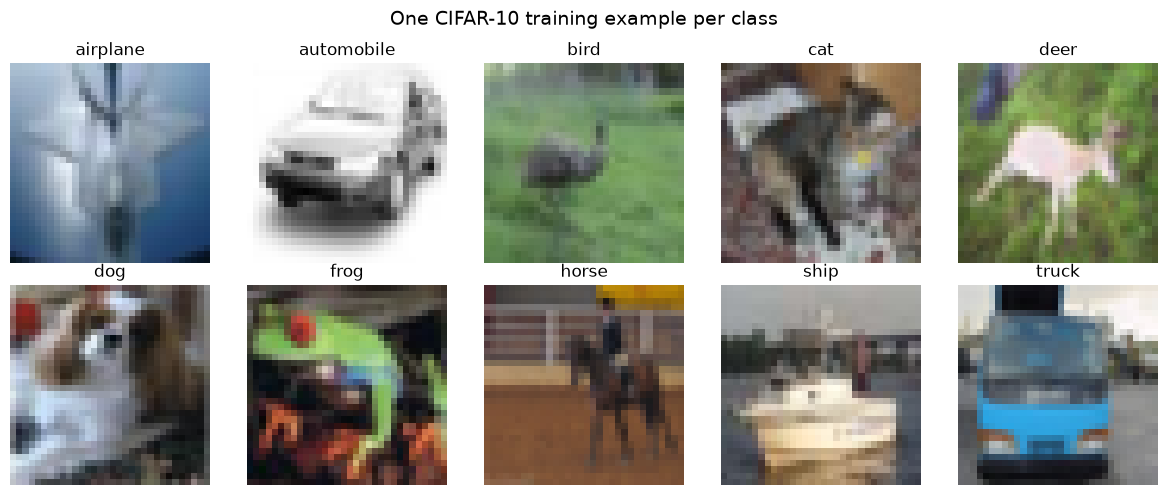

In [6]:
# Select one training example from each class without accessing test data.
example_indices = []
for class_id in range(10):
    example_indices.append(next(i for i in train_indices if targets[i] == class_id))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for class_id, (axis, dataset_index) in enumerate(zip(axes.flat, example_indices)):
    image, label = raw_dataset[dataset_index]
    axis.imshow(image.permute(1, 2, 0))
    axis.set_title(raw_dataset.classes[label])
    axis.axis("off")
fig.suptitle("One CIFAR-10 training example per class", fontsize=14)
fig.tight_layout()
plt.show()

### Test-set policy

No `train=False` CIFAR-10 dataset or test loader is created in this setup. The final model will be selected using validation data, and the standard test set will be instantiated and evaluated exactly once in Task 4.

## Task 1(a): Manual backpropagation and MLP

Backpropagation applies the chain rule from the scalar loss towards earlier operations. Each component caches the information required during its forward pass, then its `backward` method receives the gradient with respect to its output and returns the gradient with respect to its input. Parameter gradients are stored separately for later optimization.

The manual path below uses PyTorch tensors only as arrays for numerical operations. Its parameters have `requires_grad=False`, and it does not use `torch.nn` layers, `loss.backward()`, or `torch.autograd` to calculate gradients.

### Manual Linear layer

For a row-wise minibatch, a Linear layer computes

$$Y=XW+b,$$

where $X\in\mathbb{R}^{N\times D}$, $W\in\mathbb{R}^{D\times M}$, $b\in\mathbb{R}^{M}$, and $Y\in\mathbb{R}^{N\times M}$. Given upstream gradient $G=\partial L/\partial Y$, the explicit backward equations are

$$\frac{\partial L}{\partial X}=GW^T,\qquad \frac{\partial L}{\partial W}=X^TG,\qquad \frac{\partial L}{\partial b}=\sum_{n=1}^{N}G_{n,:}.$$

The loss will already supply the factor $1/N$ for mean reduction, so the Linear layer must not divide its gradients by the batch size again.

In [7]:
class ManualLinear:
    """A fully connected layer with an explicit analytical backward pass."""

    def __init__(self, in_features, out_features, *, device=None, dtype=torch.float32):
        if in_features <= 0 or out_features <= 0:
            raise ValueError("in_features and out_features must be positive")
        self.in_features = in_features
        self.out_features = out_features
        # Kaiming-style scaling is an implementation choice for the ReLU MLP.
        scale = (2.0 / in_features) ** 0.5
        self.weight = torch.randn(
            in_features, out_features, device=device, dtype=dtype
        ) * scale
        self.bias = torch.zeros(out_features, device=device, dtype=dtype)
        self.grad_weight = torch.zeros_like(self.weight)
        self.grad_bias = torch.zeros_like(self.bias)
        self._input = None

    def forward(self, inputs):
        if inputs.ndim != 2 or inputs.shape[1] != self.in_features:
            raise ValueError(
                f"Expected inputs with shape (N, {self.in_features}), "
                f"received {tuple(inputs.shape)}"
            )
        self._input = inputs
        return inputs @ self.weight + self.bias

    def backward(self, grad_output):
        if self._input is None:
            raise RuntimeError("forward must be called before backward")
        expected_shape = (self._input.shape[0], self.out_features)
        if tuple(grad_output.shape) != expected_shape:
            raise ValueError(
                f"Expected grad_output with shape {expected_shape}, "
                f"received {tuple(grad_output.shape)}"
            )
        self.grad_weight = self._input.T @ grad_output
        self.grad_bias = grad_output.sum(dim=0)
        return grad_output @ self.weight.T

### Manual ReLU

ReLU applies $A=\max(0,Z)$ elementwise. Using zero as the subgradient at $Z=0$, its backward operation is

$$G_Z=G_A\odot\mathbf{1}_{Z>0}.$$

The Boolean activation mask implements the required Jacobian-vector product directly; constructing the full diagonal Jacobian would waste memory.

In [8]:
class ManualReLU:
    """Elementwise ReLU with zero subgradient at the origin."""

    def __init__(self):
        self._positive_mask = None

    def forward(self, inputs):
        self._positive_mask = inputs > 0
        return torch.where(self._positive_mask, inputs, torch.zeros_like(inputs))

    def backward(self, grad_output):
        if self._positive_mask is None:
            raise RuntimeError("forward must be called before backward")
        if grad_output.shape != self._positive_mask.shape:
            raise ValueError("grad_output must have the same shape as the ReLU input")
        return grad_output * self._positive_mask

### Manual softmax cross-entropy

For logits $S\in\mathbb{R}^{N\times K}$, softmax assigns probability $p_{ij}=e^{S_{ij}}/\sum_k e^{S_{ik}}$. The mean cross-entropy for integer labels $y_i$ is

$$L=-\frac{1}{N}\sum_i\log p_{i,y_i}.$$

Subtracting each row's maximum logit before exponentiation leaves its probabilities unchanged and prevents overflow. Differentiating the combined loss gives

$$\frac{\partial L}{\partial S}=\frac{P-Y_{\mathrm{onehot}}}{N}.$$

The implementation uses integer indexing, so it does not need to materialize the one-hot target matrix.

In [9]:
class ManualSoftmaxCrossEntropy:
    """Numerically stable mean softmax cross-entropy with manual gradient."""

    def __init__(self):
        self._probabilities = None
        self._targets = None

    def forward(self, logits, targets):
        if logits.ndim != 2:
            raise ValueError("logits must have shape (N, K)")
        if targets.ndim != 1 or targets.shape[0] != logits.shape[0]:
            raise ValueError("targets must have shape (N,)")
        if targets.dtype != torch.long:
            raise TypeError("targets must contain torch.long class indices")
        if bool(((targets < 0) | (targets >= logits.shape[1])).any().item()):
            raise ValueError("target index is outside the class range")

        shifted_logits = logits - logits.max(dim=1, keepdim=True).values
        exp_logits = shifted_logits.exp()
        normalizers = exp_logits.sum(dim=1, keepdim=True)
        self._probabilities = exp_logits / normalizers
        self._targets = targets

        row_indices = torch.arange(logits.shape[0], device=logits.device)
        log_probabilities = shifted_logits - normalizers.log()
        return -log_probabilities[row_indices, targets].mean()

    def backward(self):
        if self._probabilities is None or self._targets is None:
            raise RuntimeError("forward must be called before backward")
        batch_size = self._targets.shape[0]
        row_indices = torch.arange(batch_size, device=self._targets.device)
        grad_logits = self._probabilities.clone()
        grad_logits[row_indices, self._targets] -= 1.0
        return grad_logits / batch_size

### Assemble the manual MLP

Each normalized CIFAR-10 image is flattened from $(3,32,32)$ to 3,072 features. The model uses one 256-unit hidden layer.

```text
(N, 3072) -> Linear(3072, 256) -> ReLU -> Linear(256, 10) -> logits
```

The backward pass traverses those components in the exact reverse order. Softmax cross-entropy remains a separate component because it converts the final logits and labels into the initial gradient for the model.

In [10]:
class ManualMLP:
    """One-hidden-layer CIFAR-10 MLP assembled from manual components."""

    def __init__(
        self, input_dim=3 * 32 * 32, hidden_dim=256, num_classes=10,
        *, device=None, dtype=torch.float32
    ):
        self.linear1 = ManualLinear(
            input_dim, hidden_dim, device=device, dtype=dtype
        )
        self.relu = ManualReLU()
        self.linear2 = ManualLinear(
            hidden_dim, num_classes, device=device, dtype=dtype
        )

    def forward(self, inputs):
        hidden_pre_activation = self.linear1.forward(inputs)
        hidden_activation = self.relu.forward(hidden_pre_activation)
        return self.linear2.forward(hidden_activation)

    def backward(self, grad_logits):
        grad_hidden = self.linear2.backward(grad_logits)
        grad_hidden_pre_activation = self.relu.backward(grad_hidden)
        return self.linear1.backward(grad_hidden_pre_activation)

    def named_parameters_and_gradients(self):
        return [
            ("linear1.weight", self.linear1.weight, self.linear1.grad_weight),
            ("linear1.bias", self.linear1.bias, self.linear1.grad_bias),
            ("linear2.weight", self.linear2.weight, self.linear2.grad_weight),
            ("linear2.bias", self.linear2.bias, self.linear2.grad_bias),
        ]

In [11]:
# A small real training minibatch checks the complete manual forward/backward path.
demo_images, demo_targets = next(iter(train_loader))
demo_inputs = demo_images[:8].reshape(8, -1).to(device)
demo_targets = demo_targets[:8].to(device)

manual_mlp = ManualMLP(hidden_dim=256, device=device)
manual_loss = ManualSoftmaxCrossEntropy()
demo_logits = manual_mlp.forward(demo_inputs)
demo_loss = manual_loss.forward(demo_logits, demo_targets)
demo_grad_logits = manual_loss.backward()
demo_grad_inputs = manual_mlp.backward(demo_grad_logits)

assert demo_logits.shape == (8, 10)
assert demo_loss.ndim == 0 and bool(torch.isfinite(demo_loss).item())
assert demo_grad_logits.shape == demo_logits.shape
assert demo_grad_inputs.shape == demo_inputs.shape
assert bool(torch.isfinite(demo_grad_inputs).all().item())
assert torch.allclose(
    manual_loss._probabilities.sum(dim=1),
    torch.ones(8, device=device),
    atol=1e-6,
)
assert torch.allclose(
    demo_grad_logits.sum(dim=1),
    torch.zeros(8, device=device),
    atol=1e-6,
)
assert demo_logits.grad_fn is None and not demo_logits.requires_grad

gradient_rows = []
for name, parameter, gradient in manual_mlp.named_parameters_and_gradients():
    assert parameter.shape == gradient.shape
    assert not parameter.requires_grad
    assert bool(torch.isfinite(gradient).all().item())
    gradient_rows.append(
        {
            "parameter": name,
            "parameter shape": str(tuple(parameter.shape)),
            "gradient shape": str(tuple(gradient.shape)),
            "gradient L2 norm": gradient.norm().item(),
        }
    )

parameter_count = sum(
    parameter.numel()
    for _, parameter, _ in manual_mlp.named_parameters_and_gradients()
)
print(f"Demo input shape: {tuple(demo_inputs.shape)}")
print(f"Logit shape: {tuple(demo_logits.shape)}")
print(f"Mean cross-entropy loss: {demo_loss.item():.6f}")
print(f"Input-gradient shape: {tuple(demo_grad_inputs.shape)}")
print(f"Trainable parameter count: {parameter_count:,}")
pd.DataFrame(gradient_rows)

Demo input shape: (8, 3072)
Logit shape: (8, 10)
Mean cross-entropy loss: 2.731329
Input-gradient shape: (8, 3072)
Trainable parameter count: 789,258


,parameter,parameter shape,gradient shape,gradient L2 norm
0,linear1.weight,"(3072, 256)","(3072, 256)",16.202597
1,linear1.bias,"(256,)","(256,)",0.389378
2,linear2.weight,"(256, 10)","(256, 10)",4.882580
3,linear2.bias,"(10,)","(10,)",0.393426


The smoke test sends eight normalized, flattened training images through the complete manual path. At random initialization it produced a finite mean loss of 2.731329; this is an implementation check rather than a classification-performance result. The $(8,10)$ logits, $(8,3072)$ input gradient, and matching parameter/gradient shapes show that the components connect correctly. Softmax probabilities sum to one, each row of its logit gradient sums to zero, and the table shows nonzero finite gradient norms for both Linear layers.

## Task 1(b): Gradient verification

A forward pass can produce plausible values even when a transpose, sign, batch average, or activation mask is wrong. The analytical gradients are therefore checked against two independent references: PyTorch autograd and centred finite differences. The checks use a tiny deterministic MLP on CPU in `float64`; perturbing every coordinate of the full CIFAR-10 model would be unnecessarily expensive.

For scalar loss $f$ and coordinate $\theta_i$, the centred finite-difference estimate is

$$g_i^{\mathrm{FD}}\approx\frac{f(\theta_i+h)-f(\theta_i-h)}{2h}.$$

The experiment uses $h=10^{-5}$. This is small enough for the $O(h^2)$ truncation error to be useful in double precision without making subtraction rounding error dominant. All MLP ReLU preactivations are checked to remain away from zero, where ReLU is not differentiable.

### Error metrics and tolerances

For each coordinate, the reported symmetric relative error is

$$r_i=\frac{|g_i^{\mathrm{manual}}-g_i^{\mathrm{reference}}|}{\max(10^{-12},|g_i^{\mathrm{manual}}|+|g_i^{\mathrm{reference}}|)}.$$

Each table entry reports $\max_i r_i$ together with the maximum absolute error. Absolute error is included because a relative error can look large when both gradients are nearly zero. `torch.allclose` checks every coordinate using $|a_i-b_i|\leq\mathrm{atol}+\mathrm{rtol}|b_i|$. The chosen tolerances are `rtol=1e-9, atol=1e-11` for analytical versus autograd gradients and `rtol=1e-5, atol=1e-7` for finite differences, whose approximation and rounding errors are larger. These are experimental choices.

In [12]:
# Build a small, smooth test case for the manual end-to-end path.
CHECK_BATCH_SIZE = 4
CHECK_INPUT_DIM = 5
CHECK_HIDDEN_DIM = 4
CHECK_NUM_CLASSES = 3
FD_STEP = 1e-5
RELATIVE_EPSILON = 1e-12
AUTOGRAD_RTOL, AUTOGRAD_ATOL = 1e-9, 1e-11
FD_RTOL, FD_ATOL = 1e-5, 1e-7
check_device = torch.device("cpu")
check_dtype = torch.float64
check_targets = torch.tensor([0, 1, 2, 1], dtype=torch.long)

# Select a deterministic point with positive and negative ReLU inputs,
# all separated from the non-differentiable value zero.
for check_seed in range(12_345, 12_445):
    torch.manual_seed(check_seed)
    check_inputs = torch.randn(
        CHECK_BATCH_SIZE, CHECK_INPUT_DIM, dtype=check_dtype
    )
    check_model = ManualMLP(
        input_dim=CHECK_INPUT_DIM,
        hidden_dim=CHECK_HIDDEN_DIM,
        num_classes=CHECK_NUM_CLASSES,
        device=check_device,
        dtype=check_dtype,
    )
    check_preactivations = (
        check_inputs @ check_model.linear1.weight + check_model.linear1.bias
    )
    minimum_relu_margin = check_preactivations.abs().min().item()
    has_both_relu_regions = bool(
        (check_preactivations > 0).any().item()
        and (check_preactivations < 0).any().item()
    )
    if minimum_relu_margin > 0.1 and has_both_relu_regions:
        break
else:
    raise RuntimeError("Could not construct a smooth deterministic ReLU test point")

check_loss_function = ManualSoftmaxCrossEntropy()
manual_check_logits = check_model.forward(check_inputs)
manual_check_loss = check_loss_function.forward(
    manual_check_logits, check_targets
)
manual_grad_logits = check_loss_function.backward().clone()
manual_grad_hidden = check_model.linear2.backward(manual_grad_logits)
manual_grad_preactivations = check_model.relu.backward(manual_grad_hidden)
manual_grad_inputs = check_model.linear1.backward(
    manual_grad_preactivations
).clone()

manual_gradients = {
    "loss logits": manual_grad_logits.clone(),
    "MLP input": manual_grad_inputs,
    "linear1.weight": check_model.linear1.grad_weight.clone(),
    "linear1.bias": check_model.linear1.grad_bias.clone(),
    "linear2.weight": check_model.linear2.grad_weight.clone(),
    "linear2.bias": check_model.linear2.grad_bias.clone(),
}

# A separate ReLU component check uses values safely away from zero.
relu_check_inputs = torch.tensor(
    [[-2.0, -0.5, 0.25, 1.5]], dtype=check_dtype
)
relu_upstream = torch.tensor(
    [[0.4, -1.2, 2.0, -0.7]], dtype=check_dtype
)
relu_check = ManualReLU()
relu_check.forward(relu_check_inputs)
manual_gradients["ReLU input"] = relu_check.backward(relu_upstream).clone()

print(f"Gradient-check seed: {check_seed}")
print(f"Minimum absolute MLP ReLU preactivation: {minimum_relu_margin:.6f}")
print(f"Manual tiny-MLP loss: {manual_check_loss.item():.12f}")

Gradient-check seed: 12345
Minimum absolute MLP ReLU preactivation: 0.124134
Manual tiny-MLP loss: 1.414826545279


### Isolated autograd reference

The following code is intentionally separate from the manual implementation. It copies the same values into leaf tensors with `requires_grad=True`, reconstructs the MLP using standard tensor operations, and calls PyTorch's `backward()` only to obtain independent reference gradients.

In [13]:
import torch.nn.functional as F

reference_inputs = check_inputs.detach().clone().requires_grad_(True)
reference_w1 = check_model.linear1.weight.detach().clone().requires_grad_(True)
reference_b1 = check_model.linear1.bias.detach().clone().requires_grad_(True)
reference_w2 = check_model.linear2.weight.detach().clone().requires_grad_(True)
reference_b2 = check_model.linear2.bias.detach().clone().requires_grad_(True)

reference_preactivations = reference_inputs @ reference_w1 + reference_b1
reference_hidden = F.relu(reference_preactivations)
reference_logits = reference_hidden @ reference_w2 + reference_b2
reference_logits.retain_grad()
reference_loss = F.cross_entropy(reference_logits, check_targets, reduction="mean")
reference_loss.backward()

autograd_gradients = {
    "loss logits": reference_logits.grad.detach().clone(),
    "MLP input": reference_inputs.grad.detach().clone(),
    "linear1.weight": reference_w1.grad.detach().clone(),
    "linear1.bias": reference_b1.grad.detach().clone(),
    "linear2.weight": reference_w2.grad.detach().clone(),
    "linear2.bias": reference_b2.grad.detach().clone(),
}

reference_relu_inputs = relu_check_inputs.detach().clone().requires_grad_(True)
reference_relu_scalar = (F.relu(reference_relu_inputs) * relu_upstream).sum()
reference_relu_scalar.backward()
autograd_gradients["ReLU input"] = reference_relu_inputs.grad.detach().clone()

assert torch.allclose(
    manual_check_loss, reference_loss.detach(), rtol=1e-12, atol=1e-12
)
print(f"Autograd tiny-MLP loss: {reference_loss.item():.12f}")

Autograd tiny-MLP loss: 1.414826545279


In [14]:
def centered_finite_difference(tensor, scalar_function, step=FD_STEP):
    """Estimate every coordinate gradient while restoring each value."""
    gradient = torch.zeros_like(tensor)
    flat_tensor = tensor.view(-1)
    flat_gradient = gradient.view(-1)

    for index in range(flat_tensor.numel()):
        original_value = flat_tensor[index].item()
        flat_tensor[index] = original_value + step
        loss_plus = scalar_function().item()
        flat_tensor[index] = original_value - step
        loss_minus = scalar_function().item()
        flat_tensor[index] = original_value
        flat_gradient[index] = (loss_plus - loss_minus) / (2.0 * step)

    return gradient

def current_manual_mlp_loss():
    logits = check_model.forward(check_inputs)
    loss_function = ManualSoftmaxCrossEntropy()
    return loss_function.forward(logits, check_targets)

finite_difference_gradients = {}
mlp_tensors_to_check = {
    "MLP input": check_inputs,
    "linear1.weight": check_model.linear1.weight,
    "linear1.bias": check_model.linear1.bias,
    "linear2.weight": check_model.linear2.weight,
    "linear2.bias": check_model.linear2.bias,
}
for name, tensor in mlp_tensors_to_check.items():
    finite_difference_gradients[name] = centered_finite_difference(
        tensor, current_manual_mlp_loss
    )

fd_logits = manual_check_logits.detach().clone()
finite_difference_gradients["loss logits"] = centered_finite_difference(
    fd_logits,
    lambda: ManualSoftmaxCrossEntropy().forward(fd_logits, check_targets),
)

fd_relu_inputs = relu_check_inputs.clone()
finite_difference_gradients["ReLU input"] = centered_finite_difference(
    fd_relu_inputs,
    lambda: (
        torch.where(fd_relu_inputs > 0, fd_relu_inputs, torch.zeros_like(fd_relu_inputs))
        * relu_upstream
    ).sum(),
)

print(f"Centred finite differences completed with h={FD_STEP:g}.")

Centred finite differences completed with h=1e-05.


In [15]:
def gradient_errors(manual, reference, epsilon=RELATIVE_EPSILON):
    absolute_error = (manual - reference).abs()
    denominator = torch.maximum(
        manual.abs() + reference.abs(),
        torch.full_like(manual, epsilon),
    )
    relative_error = absolute_error / denominator
    return absolute_error.max().item(), relative_error.max().item()

comparison_rows = []
comparison_order = [
    "ReLU input",
    "loss logits",
    "MLP input",
    "linear1.weight",
    "linear1.bias",
    "linear2.weight",
    "linear2.bias",
]
for name in comparison_order:
    manual_gradient = manual_gradients[name]
    autograd_gradient = autograd_gradients[name]
    fd_gradient = finite_difference_gradients[name]
    auto_abs, auto_rel = gradient_errors(manual_gradient, autograd_gradient)
    fd_abs, fd_rel = gradient_errors(manual_gradient, fd_gradient)
    comparison_rows.append(
        {
            "component / tensor": name,
            "autograd max abs": auto_abs,
            "autograd max relative": auto_rel,
            "autograd allclose": torch.allclose(
                manual_gradient, autograd_gradient,
                rtol=AUTOGRAD_RTOL, atol=AUTOGRAD_ATOL,
            ),
            "finite diff max abs": fd_abs,
            "finite diff max relative": fd_rel,
            "finite diff allclose": torch.allclose(
                manual_gradient, fd_gradient, rtol=FD_RTOL, atol=FD_ATOL
            ),
        }
    )

gradient_comparison = pd.DataFrame(comparison_rows).set_index(
    "component / tensor"
)
assert gradient_comparison["autograd allclose"].all()
assert gradient_comparison["finite diff allclose"].all()
gradient_comparison

,autograd max abs,autograd max relative,autograd allclose,finite diff max abs,finite diff max relative,finite diff allclose
component / tensor,,,,,,
ReLU input,0.000000e+00,0.000000e+00,True,2.075562e-12,1.482544e-12,True
loss logits,1.387779e-17,9.224733e-17,True,1.231187e-11,1.985753e-10,True
MLP input,1.387779e-17,1.261689e-16,True,9.671083e-12,1.613326e-09,True
linear1.weight,1.387779e-17,3.728108e-16,True,1.822184e-11,2.901973e-09,True
linear1.bias,6.938894e-18,8.634032e-16,True,7.965907e-12,4.922367e-10,True
linear2.weight,5.551115e-17,1.831092e-16,True,1.418252e-11,4.678248e-11,True
linear2.bias,1.387779e-17,1.016294e-16,True,1.069411e-11,7.831481e-11,True


The manual and autograd losses agree to the 12 displayed decimal places. All seven checked gradients pass `torch.allclose` against both references. The largest manual-versus-autograd relative error is $8.63\times10^{-16}$ (the first Linear bias), which is at double-precision rounding scale. The largest finite-difference relative error is $2.90\times10^{-9}$ (the first Linear weights), and the largest finite-difference absolute error is $1.82\times10^{-11}$. The finite-difference errors are slightly larger because they include truncation and floating-point subtraction error, but they remain far below the selected tolerances. The smallest MLP ReLU preactivation magnitude was 0.124134, much larger than $h=10^{-5}$, so no perturbation approached the non-differentiable ReLU boundary. Agreement for the standalone ReLU and loss together with every end-to-end input and parameter gradient supports the implemented matrix transposes, bias summation, ReLU mask, softmax derivative, and single application of the batch mean.

## Task 1(c): Train the manual MLP with SGD

Plain stochastic gradient descent updates each parameter $\theta$ using the gradient of the current minibatch loss:

$$\theta_{t+1}=\theta_t-\eta\nabla_{\theta}L_{\mathcal{B}_t}(\theta_t),$$

where $\eta$ is the learning rate and $\mathcal{B}_t$ is a shuffled minibatch. Each normalized CIFAR-10 image is flattened from $(3,32,32)$ to 3,072 features before entering the manual MLP. The manual softmax cross-entropy supplies the initial gradient, the model's explicit backward methods calculate every parameter gradient, and the parameters are updated directly without autograd or a PyTorch optimizer.

The epoch loss is the sample-weighted mean $\overline L=(\sum_{\mathcal B}|\mathcal B|L_{\mathcal B})/(\sum_{\mathcal B}|\mathcal B|)$, which correctly handles a smaller final minibatch. Validation accuracy uses $\hat y_i=\arg\max_j S_{ij}$; applying softmax is unnecessary because it preserves the order of logits.

### Experimental configuration

| Setting | Chosen value |
|---|---:|
| Architecture | 3072 → 256 → 10 |
| Activation | ReLU |
| Initialization | Kaiming-style weight scaling, zero bias |
| Optimizer | Plain manual SGD |
| Learning rate | 0.05 |
| Batch size | 128 |
| Epochs | 10 |
| Seed | 42 |

These are implementation choices because the assignment does not prescribe them. A batch size of 128 and ten epochs keep the full 45,000-image experiment practical on both a laptop and Colab, while the moderate learning rate provides repeated SGD updates without adding momentum, weight decay, or other Task 2/3 techniques. The same fixed split and training-derived normalization from Setup are reused.

In [16]:
import time

TASK1C_EPOCHS = 10
TASK1C_LEARNING_RATE = 0.05
TASK1C_BATCH_SIZE = 128
TASK1C_HIDDEN_DIM = 256

def manual_sgd_step(model, learning_rate):
    """Apply one plain SGD update using the stored manual gradients."""
    for _, parameter, gradient in model.named_parameters_and_gradients():
        parameter.add_(gradient, alpha=-learning_rate)

def validation_accuracy(model, loader, evaluation_device):
    """Compute accuracy only; no parameter updates and no test data."""
    correct = 0
    total = 0
    for images, targets in loader:
        inputs = images.flatten(start_dim=1).to(evaluation_device)
        targets = targets.to(evaluation_device)
        logits = model.forward(inputs)
        predictions = logits.argmax(dim=1)
        correct += (predictions == targets).sum().item()
        total += targets.shape[0]
    return 100.0 * correct / total

def train_manual_mlp(
    model, loss_function, training_loader, validation_loader,
    *, epochs, learning_rate, training_device
):
    history = []
    start_time = time.perf_counter()

    for epoch in range(1, epochs + 1):
        loss_sum = 0.0
        sample_count = 0

        for images, targets in training_loader:
            inputs = images.flatten(start_dim=1).to(training_device)
            targets = targets.to(training_device)

            logits = model.forward(inputs)
            loss = loss_function.forward(logits, targets)
            grad_logits = loss_function.backward()
            model.backward(grad_logits)
            manual_sgd_step(model, learning_rate)

            batch_size = targets.shape[0]
            loss_sum += loss.item() * batch_size
            sample_count += batch_size

        epoch_loss = loss_sum / sample_count
        epoch_val_accuracy = validation_accuracy(
            model, validation_loader, training_device
        )
        elapsed = time.perf_counter() - start_time
        history.append(
            {
                "epoch": epoch,
                "training loss": epoch_loss,
                "validation accuracy (%)": epoch_val_accuracy,
                "elapsed time (s)": elapsed,
            }
        )
        print(
            f"Epoch {epoch:02d}/{epochs}: loss={epoch_loss:.4f}, "
            f"validation accuracy={epoch_val_accuracy:.2f}%"
        )

    return pd.DataFrame(history)

In [17]:
# Use a fresh generator so earlier demonstration cells cannot change shuffle order.
seed_everything(SEED)
task1c_loader_generator = torch.Generator().manual_seed(SEED + 1_001)
task1c_train_loader = DataLoader(
    train_dataset,
    batch_size=TASK1C_BATCH_SIZE,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=pin_memory,
    generator=task1c_loader_generator,
)

task1c_model = ManualMLP(
    hidden_dim=TASK1C_HIDDEN_DIM, device=device, dtype=torch.float32
)
task1c_loss_function = ManualSoftmaxCrossEntropy()
task1c_history = train_manual_mlp(
    task1c_model,
    task1c_loss_function,
    task1c_train_loader,
    val_loader,
    epochs=TASK1C_EPOCHS,
    learning_rate=TASK1C_LEARNING_RATE,
    training_device=device,
)

task1c_elapsed_time = task1c_history["elapsed time (s)"].iloc[-1]
task1c_final_accuracy = task1c_history["validation accuracy (%)"].iloc[-1]
task1c_best_row = task1c_history.loc[
    task1c_history["validation accuracy (%)"].idxmax()
]
print(f"Device: {device}")
print(f"Total training time: {task1c_elapsed_time:.1f} seconds")
print(f"Final validation accuracy: {task1c_final_accuracy:.2f}%")
print(
    f"Best validation accuracy: {task1c_best_row['validation accuracy (%)']:.2f}% "
    f"at epoch {int(task1c_best_row['epoch'])}"
)

Epoch 01/10: loss=1.7600, validation accuracy=44.30%


Epoch 02/10: loss=1.4671, validation accuracy=46.90%


Epoch 03/10: loss=1.3653, validation accuracy=49.34%


Epoch 04/10: loss=1.2992, validation accuracy=45.30%


Epoch 05/10: loss=1.2470, validation accuracy=47.64%


Epoch 06/10: loss=1.1956, validation accuracy=48.90%


Epoch 07/10: loss=1.1527, validation accuracy=47.64%


Epoch 08/10: loss=1.1156, validation accuracy=47.54%


Epoch 09/10: loss=1.0859, validation accuracy=44.16%


Epoch 10/10: loss=1.0534, validation accuracy=46.76%
Device: mps
Total training time: 20.1 seconds
Final validation accuracy: 46.76%
Best validation accuracy: 49.34% at epoch 3


In [18]:
task1c_results_table = task1c_history.copy()
task1c_results_table["training loss"] = task1c_results_table[
    "training loss"
].round(4)
task1c_results_table["validation accuracy (%)"] = task1c_results_table[
    "validation accuracy (%)"
].round(2)
task1c_results_table["elapsed time (s)"] = task1c_results_table[
    "elapsed time (s)"
].round(1)
task1c_results_table.set_index("epoch")

,training loss,validation accuracy (%),elapsed time (s)
epoch,,,
1,1.7600,44.30,2.1
2,1.4671,46.90,4.1
3,1.3653,49.34,6.1
4,1.2992,45.30,8.1
5,1.2470,47.64,10.1
6,1.1956,48.90,12.1
7,1.1527,47.64,14.1
8,1.1156,47.54,16.1
9,1.0859,44.16,18.1


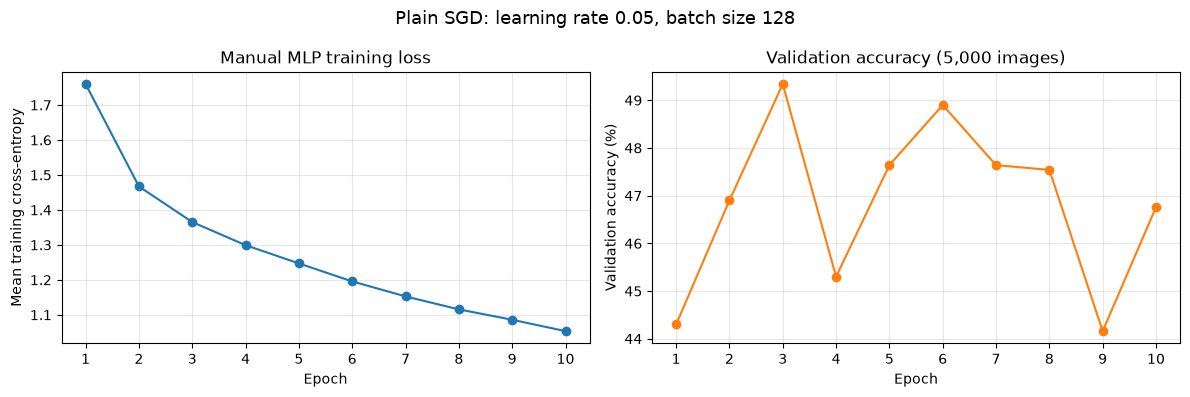

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs = task1c_history["epoch"]

axes[0].plot(
    epochs, task1c_history["training loss"], marker="o", color="tab:blue"
)
axes[0].set(
    xlabel="Epoch", ylabel="Mean training cross-entropy",
    title="Manual MLP training loss",
)
axes[0].set_xticks(epochs)
axes[0].grid(alpha=0.3)

axes[1].plot(
    epochs, task1c_history["validation accuracy (%)"],
    marker="o", color="tab:orange"
)
axes[1].set(
    xlabel="Epoch", ylabel="Validation accuracy (%)",
    title="Validation accuracy (5,000 images)",
)
axes[1].set_xticks(epochs)
axes[1].grid(alpha=0.3)

fig.suptitle(
    f"Plain SGD: learning rate {TASK1C_LEARNING_RATE}, "
    f"batch size {TASK1C_BATCH_SIZE}",
    fontsize=13,
)
fig.tight_layout()
plt.show()

The mean training loss decreases every epoch, from 1.7600 to 1.0534, so the manually calculated gradients and plain SGD updates consistently optimize the training objective. Validation accuracy initially rises from 44.30% to its best value of 49.34% at epoch 3, but then fluctuates between 44.16% and 48.90% and finishes at 46.76%. Therefore, the continued decrease in training loss after epoch 3 does not translate into steadily improving performance on unseen validation images. This pattern is consistent with increasing fit to the training data together with validation variability; without training-set accuracy or repeated runs, it should not be treated as proof of overfitting alone. The flattened MLP also discards the two-dimensional locality that a CNN can exploit, which limits its image-classification inductive bias. The complete ten-epoch run took 20.3 seconds on Apple MPS, and the standard CIFAR-10 test is unused.

## Task 1(d): Gradient propagation through a 10-layer MLP

For sigmoid,

$$\sigma(z)=\frac{1}{1+e^{-z}},\qquad \sigma'(z)=\sigma(z)(1-\sigma(z))\leq\frac14.$$

For ReLU, using zero as the derivative at the origin,

$$\operatorname{ReLU}(z)=\max(0,z),\qquad \operatorname{ReLU}'(z)=\mathbf{1}_{z>0}.$$

Backpropagation through hidden layer $\ell$ repeatedly multiplies by weights and activation derivatives:

$$\delta_\ell=(\delta_{\ell+1}W_{\ell+1}^T)\odot\phi'(z_\ell).$$

Products whose typical magnitude is below one can attenuate gradients towards the input. Sigmoid contributes a local multiplier no larger than $1/4$ at every hidden layer and an even smaller multiplier when saturated. ReLU passes the upstream value unchanged at positive preactivations and blocks it at non-positive ones, so it can reduce this source of attenuation but does not guarantee stable gradients.

### Controlled comparison at initialization

This notebook defines a **10-layer MLP** as ten learnable Linear layers in total: nine hidden Linear layers of width 128, each followed by sigmoid or ReLU, and one 10-class output Linear layer without a hidden activation. Both networks receive the same fixed 128-image normalized training minibatch and labels. They start from identical Xavier-normal weights, with standard deviation $\sqrt{2/(n_{\mathrm{in}}+n_{\mathrm{out}})}$, and identical zero biases. Xavier is used as a shared neutral policy so activation is the controlled difference.

Exactly one forward and backward pass is performed before any parameter update. For Linear layer $\ell$, the plotted value is the Frobenius norm

$$g_\ell=\|\nabla_{W_\ell}L\|_F=\sqrt{\sum_{i,j}(\nabla_{W_\ell}L)_{ij}^2}.$$

Layer 1 is closest to the input and layer 10 is the output layer. A logarithmic vertical axis is used because depth can produce differences spanning several orders of magnitude.

In [20]:
class ManualSigmoid:
    """Elementwise sigmoid with an explicit analytical backward pass."""

    def __init__(self):
        self._output = None

    def forward(self, inputs):
        self._output = torch.sigmoid(inputs)
        return self._output

    def backward(self, grad_output):
        if self._output is None:
            raise RuntimeError("forward must be called before backward")
        if grad_output.shape != self._output.shape:
            raise ValueError("grad_output must have the activation shape")
        return grad_output * self._output * (1.0 - self._output)

class ManualDeepMLP:
    """A manual MLP with a configurable hidden activation."""

    def __init__(
        self, layer_dimensions, activation_name, *, device=None, dtype=torch.float32
    ):
        if len(layer_dimensions) < 2:
            raise ValueError("At least an input and output dimension are required")
        if activation_name not in {"sigmoid", "relu"}:
            raise ValueError("activation_name must be 'sigmoid' or 'relu'")

        self.activation_name = activation_name
        self.linear_layers = [
            ManualLinear(fan_in, fan_out, device=device, dtype=dtype)
            for fan_in, fan_out in zip(layer_dimensions[:-1], layer_dimensions[1:])
        ]
        activation_type = ManualSigmoid if activation_name == "sigmoid" else ManualReLU
        self.activations = [
            activation_type() for _ in range(len(self.linear_layers) - 1)
        ]

    def load_parameters(self, weights, biases):
        if len(weights) != len(self.linear_layers) or len(biases) != len(self.linear_layers):
            raise ValueError("One weight and bias tensor are required per Linear layer")
        for layer, weight, bias in zip(self.linear_layers, weights, biases):
            if layer.weight.shape != weight.shape or layer.bias.shape != bias.shape:
                raise ValueError("Shared parameter shape does not match the architecture")
            layer.weight = weight.to(
                device=layer.weight.device, dtype=layer.weight.dtype
            ).clone()
            layer.bias = bias.to(
                device=layer.bias.device, dtype=layer.bias.dtype
            ).clone()
            layer.grad_weight = torch.zeros_like(layer.weight)
            layer.grad_bias = torch.zeros_like(layer.bias)

    def forward(self, inputs):
        output = inputs
        for index, linear_layer in enumerate(self.linear_layers):
            output = linear_layer.forward(output)
            if index < len(self.activations):
                output = self.activations[index].forward(output)
        return output

    def backward(self, grad_logits):
        gradient = grad_logits
        for index in reversed(range(len(self.linear_layers))):
            gradient = self.linear_layers[index].backward(gradient)
            if index > 0:
                gradient = self.activations[index - 1].backward(gradient)
        return gradient

    def weight_gradient_norms(self):
        return [layer.grad_weight.norm().item() for layer in self.linear_layers]

In [21]:
TASK1D_HIDDEN_WIDTH = 128
TASK1D_HIDDEN_LAYERS = 9
TASK1D_LINEAR_LAYERS = TASK1D_HIDDEN_LAYERS + 1
TASK1D_BATCH_SIZE = 128
TASK1D_SEED = SEED + 2_002
task1d_dimensions = (
    [3 * 32 * 32]
    + [TASK1D_HIDDEN_WIDTH] * TASK1D_HIDDEN_LAYERS
    + [10]
)
assert len(task1d_dimensions) - 1 == TASK1D_LINEAR_LAYERS == 10

task1d_loader = DataLoader(
    train_dataset, batch_size=TASK1D_BATCH_SIZE, shuffle=False, num_workers=0
)
task1d_images, task1d_targets = next(iter(task1d_loader))
task1d_inputs = task1d_images.flatten(start_dim=1).to(device)
task1d_targets = task1d_targets.to(device)

# Generate one shared Xavier-normal parameter set on CPU for exact matching.
task1d_generator = torch.Generator().manual_seed(TASK1D_SEED)
shared_weights = []
shared_biases = []
for fan_in, fan_out in zip(task1d_dimensions[:-1], task1d_dimensions[1:]):
    xavier_std = (2.0 / (fan_in + fan_out)) ** 0.5
    shared_weights.append(
        torch.randn(fan_in, fan_out, generator=task1d_generator) * xavier_std
    )
    shared_biases.append(torch.zeros(fan_out))

sigmoid_deep_mlp = ManualDeepMLP(
    task1d_dimensions, "sigmoid", device=device, dtype=torch.float32
)
relu_deep_mlp = ManualDeepMLP(
    task1d_dimensions, "relu", device=device, dtype=torch.float32
)
sigmoid_deep_mlp.load_parameters(shared_weights, shared_biases)
relu_deep_mlp.load_parameters(shared_weights, shared_biases)

for sigmoid_layer, relu_layer in zip(
    sigmoid_deep_mlp.linear_layers, relu_deep_mlp.linear_layers
):
    assert torch.equal(sigmoid_layer.weight, relu_layer.weight)
    assert torch.equal(sigmoid_layer.bias, relu_layer.bias)

sigmoid_loss_function = ManualSoftmaxCrossEntropy()
sigmoid_logits = sigmoid_deep_mlp.forward(task1d_inputs)
sigmoid_initial_loss = sigmoid_loss_function.forward(
    sigmoid_logits, task1d_targets
)
sigmoid_deep_mlp.backward(sigmoid_loss_function.backward())

relu_loss_function = ManualSoftmaxCrossEntropy()
relu_logits = relu_deep_mlp.forward(task1d_inputs)
relu_initial_loss = relu_loss_function.forward(relu_logits, task1d_targets)
relu_deep_mlp.backward(relu_loss_function.backward())

sigmoid_gradient_norms = sigmoid_deep_mlp.weight_gradient_norms()
relu_gradient_norms = relu_deep_mlp.weight_gradient_norms()
assert all(value > 0 and np.isfinite(value) for value in sigmoid_gradient_norms)
assert all(value > 0 and np.isfinite(value) for value in relu_gradient_norms)

print(f"Linear layers: {TASK1D_LINEAR_LAYERS} (9 hidden + 1 output)")
print(f"Fixed training minibatch: {TASK1D_BATCH_SIZE} images")
print(f"Sigmoid initial loss: {sigmoid_initial_loss.item():.6f}")
print(f"ReLU initial loss: {relu_initial_loss.item():.6f}")

Linear layers: 10 (9 hidden + 1 output)
Fixed training minibatch: 128 images
Sigmoid initial loss: 2.552745
ReLU initial loss: 2.301480


In [22]:
task1d_layer_numbers = np.arange(1, TASK1D_LINEAR_LAYERS + 1)
task1d_gradient_table = pd.DataFrame(
    {
        "layer": task1d_layer_numbers,
        "weight shape": [
            str(tuple(layer.weight.shape))
            for layer in sigmoid_deep_mlp.linear_layers
        ],
        "sigmoid gradient norm": sigmoid_gradient_norms,
        "ReLU gradient norm": relu_gradient_norms,
        "ReLU / sigmoid ratio": np.asarray(relu_gradient_norms)
        / np.asarray(sigmoid_gradient_norms),
    }
).set_index("layer")
task1d_gradient_table

,weight shape,sigmoid gradient norm,ReLU gradient norm,ReLU / sigmoid ratio
layer,,,,
1,"(3072, 128)",0.000015,0.270886,17658.976759
2,"(128, 128)",0.000017,0.076111,4378.741611
3,"(128, 128)",0.000072,0.080423,1123.855297
4,"(128, 128)",0.000315,0.088124,279.990592
5,"(128, 128)",0.001377,0.096407,70.009130
6,"(128, 128)",0.005408,0.081490,15.069501
7,"(128, 128)",0.026464,0.100906,3.813031
8,"(128, 128)",0.100295,0.109711,1.093891
9,"(128, 128)",0.469035,0.097514,0.207904


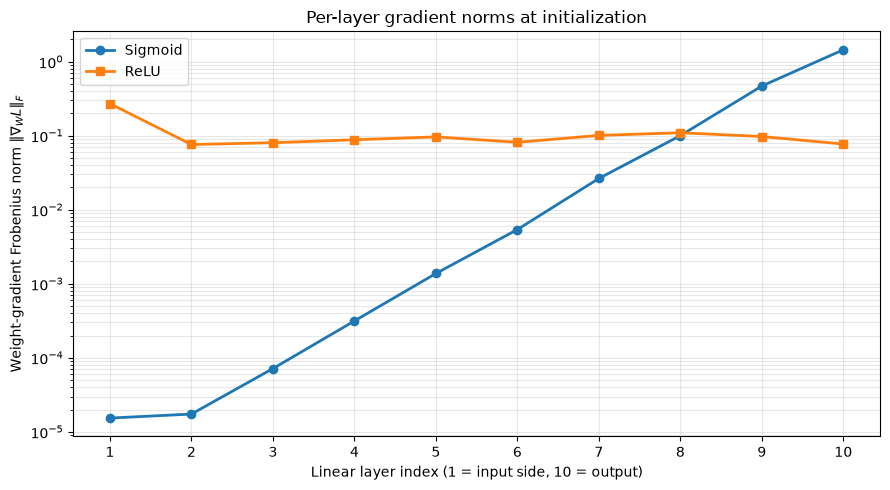

In [23]:
fig, axis = plt.subplots(figsize=(9, 5))
axis.plot(
    task1d_layer_numbers, sigmoid_gradient_norms, marker="o",
    linewidth=2, label="Sigmoid",
)
axis.plot(
    task1d_layer_numbers, relu_gradient_norms, marker="s",
    linewidth=2, label="ReLU",
)
axis.set_yscale("log")
axis.set_xticks(task1d_layer_numbers)
axis.set(
    xlabel="Linear layer index (1 = input side, 10 = output)",
    ylabel=r"Weight-gradient Frobenius norm $\|\nabla_W L\|_F$",
    title="Per-layer gradient norms at initialization",
)
axis.grid(True, which="both", alpha=0.3)
axis.legend()
fig.tight_layout()
plt.show()

The sigmoid network shows strong gradient attenuation toward the input. Its weight-gradient norm is about $1.5\times10^{-5}$ at layer 1 and rises to 1.45 at the output layer, a gap of nearly five orders of magnitude. This fits with repeatedly multiplying by nine sigmoid derivatives, each bounded by $1/4$, along with the weight matrices in between.

The ReLU norms stay between about $7.6\times10^{-2}$ and $2.7\times10^{-1}$, so gradients keep a similar order of magnitude across depth. ReLU passes gradients through on positive paths instead of shrinking them by at most $1/4$, though its zero mask and the weights still shape the non-monotonic curve. Its large layer-1 norm also partly comes from the $(3072,128)$ weight matrix having more elements than the hidden layers, since a Frobenius norm is not normalized by parameter count.

At layer 1, ReLU is over 17,000 times larger than sigmoid, yet sigmoid exceeds ReLU in the final two layers. That is possible because the activations produce different logits, losses, and output gradients even with identical parameters.

The shared Xavier initialization isolates the activation effect, but this does not prove ReLU always prevents vanishing gradients. Different widths, data, or initialization (such as Kaiming for ReLU) could change both curves. No optimizer update was applied, so all values describe gradient propagation at initialization.

# Task 2: Optimizers

## Task 2(a): Momentum SGD and bias-corrected Adam

### Update rules

For a gradient $g_t=\nabla_\theta L(\theta_{t-1})$, momentum SGD stores a gradient buffer and updates

$$v_t=\rho v_{t-1}+g_t, \qquad \theta_t=\theta_{t-1}-\eta v_t.$$

Gradients that repeatedly point in the same direction reinforce one another, while opposing components can cancel. This can reduce oscillation in high-curvature directions and retain progress in consistent directions. It is not a guarantee of faster convergence on every problem. The implementation below follows `torch.optim.SGD` semantics by initializing each parameter's momentum buffer from its first gradient. It implements the standard momentum case; weight decay, dampening, Nesterov momentum and maximization are outside this implementation.

Adam stores exponential moving averages of the gradient and its element-wise square:

$$m_t=\beta_1m_{t-1}+(1-\beta_1)g_t, \qquad v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2.$$

Because both start at zero, the early estimates are biased towards zero. Adam corrects them before updating the parameter:

$$\hat m_t=\frac{m_t}{1-\beta_1^t}, \qquad \hat v_t=\frac{v_t}{1-\beta_2^t}, \qquad \theta_t=\theta_{t-1}-\eta\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}.$$


In [24]:
class MomentumSGD(torch.optim.Optimizer):
    """SGD with a PyTorch-compatible momentum buffer for the required case."""

    def __init__(self, params, lr=1e-3, momentum=0.9):
        if lr < 0:
            raise ValueError(f"Invalid learning rate: {lr}")
        if momentum < 0:
            raise ValueError(f"Invalid momentum value: {momentum}")
        super().__init__(params, {"lr": lr, "momentum": momentum})

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            learning_rate = group["lr"]
            momentum = group["momentum"]
            for parameter in group["params"]:
                if parameter.grad is None:
                    continue
                gradient = parameter.grad
                if gradient.is_sparse:
                    raise RuntimeError("MomentumSGD does not support sparse gradients")

                state = self.state[parameter]
                if "momentum_buffer" not in state:
                    buffer = state["momentum_buffer"] = gradient.detach().clone()
                else:
                    buffer = state["momentum_buffer"]
                    buffer.mul_(momentum).add_(gradient)
                parameter.add_(buffer, alpha=-learning_rate)

        return loss

In [25]:
class BiasCorrectedAdam(torch.optim.Optimizer):
    """Classical Adam with per-parameter moments and bias correction."""

    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        if lr < 0:
            raise ValueError(f"Invalid learning rate: {lr}")
        if not 0 <= betas[0] < 1:
            raise ValueError(f"Invalid beta_1 value: {betas[0]}")
        if not 0 <= betas[1] < 1:
            raise ValueError(f"Invalid beta_2 value: {betas[1]}")
        if eps < 0:
            raise ValueError(f"Invalid epsilon value: {eps}")
        super().__init__(params, {"lr": lr, "betas": betas, "eps": eps})

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            learning_rate = group["lr"]
            beta1, beta2 = group["betas"]
            epsilon = group["eps"]
            for parameter in group["params"]:
                if parameter.grad is None:
                    continue
                gradient = parameter.grad
                if gradient.is_sparse:
                    raise RuntimeError("BiasCorrectedAdam does not support sparse gradients")

                state = self.state[parameter]
                if len(state) == 0:
                    state["step"] = 0
                    state["exp_avg"] = torch.zeros_like(parameter)
                    state["exp_avg_sq"] = torch.zeros_like(parameter)

                state["step"] += 1
                step = state["step"]
                first_moment = state["exp_avg"]
                second_moment = state["exp_avg_sq"]
                first_moment.mul_(beta1).add_(gradient, alpha=1 - beta1)
                second_moment.mul_(beta2).addcmul_(
                    gradient, gradient, value=1 - beta2
                )

                bias_correction1 = 1 - beta1 ** step
                bias_correction2 = 1 - beta2 ** step
                step_size = learning_rate / bias_correction1
                denominator = (
                    second_moment.sqrt() / bias_correction2 ** 0.5
                ).add_(epsilon)
                parameter.addcdiv_(first_moment, denominator, value=-step_size)

        return loss

### Deterministic parity test

A one-step check can miss errors in a stateful optimizer. The following experiment therefore applies six different, nonzero gradients to two parameter tensors. Each custom optimizer and its PyTorch reference receive independent parameter clones, identical gradients, identical float64 arithmetic and identical hyperparameters. Weight decay is zero and optional variants are disabled. After every step, the parameters and the stored momentum or moment tensors are compared.

For parameters $a$ and reference values $b$, the reported relative error is $\max_i |a_i-b_i|/\max(10^{-15},|a_i|,|b_i|)$. The checks use `torch.allclose(rtol=1e-12, atol=1e-14)`.

In [26]:
OPTIMIZER_RTOL = 1e-12
OPTIMIZER_ATOL = 1e-14
OPTIMIZER_STEPS = 6

def maximum_errors(custom_tensors, reference_tensors):
    max_absolute_error = 0.0
    max_relative_error = 0.0
    for custom_tensor, reference_tensor in zip(custom_tensors, reference_tensors):
        absolute_error = (custom_tensor - reference_tensor).abs()
        denominator = torch.maximum(
            torch.maximum(custom_tensor.abs(), reference_tensor.abs()),
            torch.full_like(custom_tensor, 1e-15),
        )
        max_absolute_error = max(max_absolute_error, absolute_error.max().item())
        max_relative_error = max(
            max_relative_error, (absolute_error / denominator).max().item()
        )
    return max_absolute_error, max_relative_error

def tensors_allclose(custom_tensors, reference_tensors):
    return all(
        torch.allclose(custom, reference, rtol=OPTIMIZER_RTOL, atol=OPTIMIZER_ATOL)
        for custom, reference in zip(custom_tensors, reference_tensors)
    )

def prescribed_gradients(initial_tensors, step):
    return [
        torch.sin(tensor * (step + index + 0.5))
        + 0.07 * step - 0.03 * index
        for index, tensor in enumerate(initial_tensors)
    ]

In [27]:
initial_optimizer_tensors = [
    torch.tensor([[0.35, -0.80, 1.20], [-1.10, 0.25, 0.60]], dtype=torch.float64),
    torch.tensor([0.40, -0.15, 0.90, -1.30], dtype=torch.float64),
]

optimizer_cases = [
    {
        "name": "Momentum SGD",
        "custom": MomentumSGD,
        "reference": torch.optim.SGD,
        "kwargs": {"lr": 0.05, "momentum": 0.9},
        "state keys": ("momentum_buffer",),
    },
    {
        "name": "Adam",
        "custom": BiasCorrectedAdam,
        "reference": torch.optim.Adam,
        "kwargs": {"lr": 0.01, "betas": (0.9, 0.999), "eps": 1e-8},
        "state keys": ("exp_avg", "exp_avg_sq"),
    },
]

parity_records = []
for case in optimizer_cases:
    custom_parameters = [
        torch.nn.Parameter(tensor.clone()) for tensor in initial_optimizer_tensors
    ]
    reference_parameters = [
        torch.nn.Parameter(tensor.clone()) for tensor in initial_optimizer_tensors
    ]
    custom_optimizer = case["custom"](custom_parameters, **case["kwargs"])
    reference_optimizer = case["reference"](
        reference_parameters, **case["kwargs"]
    )

    for step in range(1, OPTIMIZER_STEPS + 1):
        gradients = prescribed_gradients(initial_optimizer_tensors, step)
        for custom_parameter, reference_parameter, gradient in zip(
            custom_parameters, reference_parameters, gradients
        ):
            custom_parameter.grad = gradient.clone()
            reference_parameter.grad = gradient.clone()

        custom_optimizer.step()
        reference_optimizer.step()

        parameter_abs_error, parameter_rel_error = maximum_errors(
            custom_parameters, reference_parameters
        )
        custom_states = [
            custom_optimizer.state[parameter][key]
            for parameter in custom_parameters for key in case["state keys"]
        ]
        reference_states = [
            reference_optimizer.state[parameter][key]
            for parameter in reference_parameters for key in case["state keys"]
        ]
        state_abs_error, _ = maximum_errors(custom_states, reference_states)

        parity_records.append(
            {
                "optimizer": case["name"],
                "step": step,
                "max parameter absolute error": parameter_abs_error,
                "max parameter relative error": parameter_rel_error,
                "max state absolute error": state_abs_error,
                "parameters allclose": tensors_allclose(
                    custom_parameters, reference_parameters
                ),
                "states allclose": tensors_allclose(custom_states, reference_states),
            }
        )

optimizer_parity_table = pd.DataFrame(parity_records)
assert optimizer_parity_table["parameters allclose"].all()
assert optimizer_parity_table["states allclose"].all()
optimizer_parity_table

,optimizer,step,max parameter absolute error,max parameter relative error,max state absolute error,parameters allclose,states allclose
0,Momentum SGD,1,0.0,0.0,0.000000e+00,True,True
1,Momentum SGD,2,0.0,0.0,0.000000e+00,True,True
2,Momentum SGD,3,0.0,0.0,0.000000e+00,True,True
3,Momentum SGD,4,0.0,0.0,0.000000e+00,True,True
4,Momentum SGD,5,0.0,0.0,0.000000e+00,True,True
5,Momentum SGD,6,0.0,0.0,0.000000e+00,True,True
6,Adam,1,0.0,0.0,0.000000e+00,True,True
7,Adam,2,0.0,0.0,2.775558e-17,True,True
8,Adam,3,0.0,0.0,2.775558e-17,True,True
9,Adam,4,0.0,0.0,4.163336e-17,True,True


In [28]:
optimizer_parity_summary = (
    optimizer_parity_table.groupby("optimizer", sort=False)
    .agg(
        steps_checked=("step", "count"),
        maximum_parameter_absolute_error=("max parameter absolute error", "max"),
        maximum_parameter_relative_error=("max parameter relative error", "max"),
        maximum_state_absolute_error=("max state absolute error", "max"),
        all_parameter_checks_pass=("parameters allclose", "all"),
        all_state_checks_pass=("states allclose", "all"),
    )
)
optimizer_parity_summary

,steps_checked,maximum_parameter_absolute_error,maximum_parameter_relative_error,maximum_state_absolute_error,all_parameter_checks_pass,all_state_checks_pass
optimizer,,,,,,
Momentum SGD,6,0.0,0.0,0.000000e+00,True,True
Adam,6,0.0,0.0,4.163336e-17,True,True


Across all six stateful updates and both parameter tensors, the custom momentum SGD and Adam parameters are numerically identical to their PyTorch references: the maximum parameter absolute and relative errors are both 0.0. Every parameter and state `torch.allclose` check passes. The momentum buffers also match exactly; Adam's largest moment-state absolute difference is only $4.16\times10^{-17}$, which is rounding at float64 precision and does not change the parameter trajectory. The conclusion therefore uses the full multi-step trajectories rather than only the first update. Momentum SGD used $\eta=0.05$ and $\rho=0.9$; Adam used $\eta=0.01$, $(\beta_1,\beta_2)=(0.9,0.999)$ and $\epsilon=10^{-8}$. All calculations used CPU float64 with `rtol=1e-12` and `atol=1e-14`. This verifies the required update rules under the explicitly supported settings; it does not claim parity for the optional optimizer features excluded above.

## Task 2(b): Optimizer trajectories on an ill-conditioned quadratic

The assigned objective, its gradient and its Hessian are

$$f(x,y)=\frac{1}{2}(x^2+50y^2), \qquad \nabla f(x,y)=\begin{bmatrix}x\\50y\end{bmatrix}, \qquad \nabla^2 f=\begin{bmatrix}1&0\\0&50\end{bmatrix}.$$

The unique minimum is $(0,0)$ with $f=0$. The Hessian eigenvalues are 1 and 50, giving condition number $\kappa=50$. A contour at level $c$ satisfies $x^2+50y^2=2c$, so the contours are ellipses that are narrow in the high-curvature $y$ direction.

For plain SGD on this deterministic objective, the update is exactly gradient descent because there is no minibatch sampling. Its coordinates obey

$$x_{t+1}=(1-\eta)x_t, \qquad y_{t+1}=(1-50\eta)y_t.$$

Both coordinates converge only when $0<\eta<0.04$. For $0.02<\eta<0.04$, the multiplier of $y_t$ is negative, so the trajectory alternates across the narrow valley while converging. Momentum retains a history of these gradients, whereas Adam uses bias-corrected first and second moments to rescale the coordinates. Their observed behavior still depends on the selected hyperparameters.

### Controlled trajectory experiment

All methods start at $(-4,1)$, use float64 arithmetic and take 60 updates using the analytical gradient. Plain SGD and momentum SGD both use $\eta=0.035$, which is inside the stable interval but makes the steep-direction sign changes visible; momentum uses $\rho=0.9$. Adam uses $\eta=0.12$, $(\beta_1,\beta_2)=(0.9,0.999)$ and $\epsilon=10^{-8}$. Adam needs a different numerical learning-rate scale because it divides its first moment by the square root of its second moment. The custom Task 2(a) implementations are used for momentum SGD and Adam.

In [29]:
TASK2B_START = torch.tensor([-4.0, 1.0], dtype=torch.float64)
TASK2B_STEPS = 60

def quadratic_objective(point):
    x, y = point
    return 0.5 * (x.square() + 50.0 * y.square())

def quadratic_gradient(point):
    x, y = point
    return torch.stack((x, 50.0 * y))

def collect_optimizer_trajectory(optimizer_factory, steps=TASK2B_STEPS):
    point = torch.nn.Parameter(TASK2B_START.clone())
    optimizer = optimizer_factory([point])
    points = [point.detach().clone()]
    objectives = [quadratic_objective(point.detach()).item()]

    for _ in range(steps):
        point.grad = quadratic_gradient(point.detach())
        optimizer.step()
        points.append(point.detach().clone())
        objectives.append(quadratic_objective(point.detach()).item())

    return torch.stack(points).numpy(), np.asarray(objectives)

task2b_optimizer_settings = {
    "SGD": {
        "factory": lambda parameters: torch.optim.SGD(parameters, lr=0.035),
        "learning rate": 0.035,
        "other settings": "none",
    },
    "SGD + momentum": {
        "factory": lambda parameters: MomentumSGD(
            parameters, lr=0.035, momentum=0.9
        ),
        "learning rate": 0.035,
        "other settings": "momentum=0.9",
    },
    "Adam": {
        "factory": lambda parameters: BiasCorrectedAdam(
            parameters, lr=0.12, betas=(0.9, 0.999), eps=1e-8
        ),
        "learning rate": 0.12,
        "other settings": "betas=(0.9, 0.999), eps=1e-8",
    },
}

task2b_trajectories = {}
task2b_objectives = {}
for name, settings in task2b_optimizer_settings.items():
    trajectory, objectives = collect_optimizer_trajectory(settings["factory"])
    task2b_trajectories[name] = trajectory
    task2b_objectives[name] = objectives

assert all(path.shape == (TASK2B_STEPS + 1, 2) for path in task2b_trajectories.values())
assert all(np.array_equal(path[0], TASK2B_START.numpy()) for path in task2b_trajectories.values())

In [30]:
task2b_records = []
for name, settings in task2b_optimizer_settings.items():
    final_x, final_y = task2b_trajectories[name][-1]
    final_gradient_norm = np.hypot(final_x, 50.0 * final_y)
    task2b_records.append(
        {
            "optimizer": name,
            "learning rate": settings["learning rate"],
            "other settings": settings["other settings"],
            "updates": TASK2B_STEPS,
            "final x": final_x,
            "final y": final_y,
            "final objective": task2b_objectives[name][-1],
            "final gradient norm": final_gradient_norm,
        }
    )

task2b_results = pd.DataFrame(task2b_records).set_index("optimizer")
task2b_results

,learning rate,other settings,updates,final x,final y,final objective,final gradient norm
optimizer,,,,,,,
SGD,0.035,none,60,-0.471736,3.189156e-08,0.111267,0.471736
SGD + momentum,0.035,momentum=0.9,60,0.014021,-3.543126e-02,0.031483,1.771619
Adam,0.120,"betas=(0.9, 0.999), eps=1e-8",60,0.177423,7.090060e-03,0.016996,0.396423


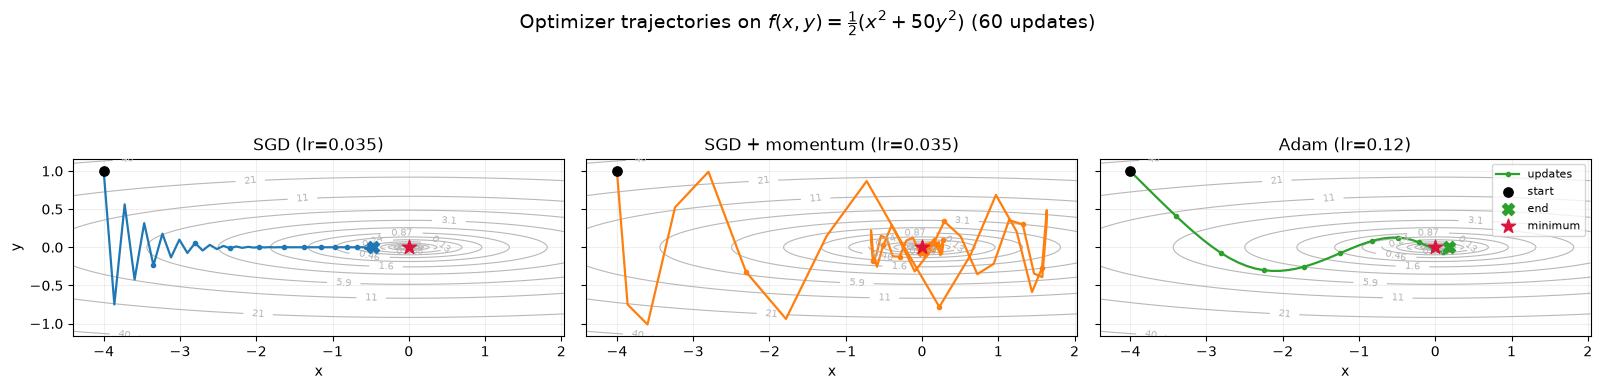

In [31]:
all_task2b_points = np.concatenate(list(task2b_trajectories.values()), axis=0)
x_limits = (
    min(-0.5, all_task2b_points[:, 0].min() - 0.4),
    max(0.5, all_task2b_points[:, 0].max() + 0.4),
)
y_extent = max(1.15, np.abs(all_task2b_points[:, 1]).max() + 0.15)
y_limits = (-y_extent, y_extent)
grid_x = np.linspace(*x_limits, 500)
grid_y = np.linspace(*y_limits, 500)
X, Y = np.meshgrid(grid_x, grid_y)
Z = 0.5 * (X**2 + 50.0 * Y**2)
contour_levels = np.geomspace(0.01, 40.0, 14)
trajectory_colors = {
    "SGD": "tab:blue",
    "SGD + momentum": "tab:orange",
    "Adam": "tab:green",
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharex=True, sharey=True)
for axis, (name, trajectory) in zip(axes, task2b_trajectories.items()):
    contours = axis.contour(
        X, Y, Z, levels=contour_levels, colors="0.72", linewidths=0.8
    )
    axis.clabel(contours, inline=True, fontsize=7, fmt="%.2g")
    color = trajectory_colors[name]
    axis.plot(
        trajectory[:, 0], trajectory[:, 1], color=color, linewidth=1.6,
        marker="o", markersize=3, markevery=5, label="updates",
    )
    axis.scatter(*trajectory[0], color="black", s=45, zorder=4, label="start")
    axis.scatter(
        *trajectory[-1], color=color, marker="X", s=75, zorder=5, label="end"
    )
    axis.scatter(0, 0, color="crimson", marker="*", s=110, zorder=5, label="minimum")
    axis.set(
        title=f"{name} (lr={task2b_optimizer_settings[name]['learning rate']})",
        xlabel="x", xlim=x_limits, ylim=y_limits,
    )
    axis.set_aspect("equal", adjustable="box")
    axis.grid(alpha=0.2)
axes[0].set_ylabel("y")
axes[-1].legend(loc="upper right", fontsize=8)
fig.suptitle(
    r"Optimizer trajectories on $f(x,y)=\frac{1}{2}(x^2+50y^2)$ (60 updates)",
    fontsize=14,
)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

The elongated contours show the $50{:}1$ curvature imbalance: a small vertical displacement changes the objective far more than the same horizontal displacement. With $\eta=0.035$, plain SGD has $y_{t+1}=-0.75y_t$, so its path repeatedly crosses the valley while $x$ contracts slowly by a factor of 0.965. After 60 updates it reaches $(-0.4717,3.19\times10^{-8})$ and $f=0.1113$: the steep coordinate has effectively converged, but substantial error remains along the shallow direction. Momentum uses the same learning rate and carries velocity across steps. Its wider early overshoots show that momentum does not automatically remove oscillation at every tuning, but the accumulated motion advances much faster in $x$, reaching $(0.0140,-0.0354)$ and $f=0.0315$. Its final gradient norm is still 1.7716 because even the small residual $y$ is multiplied by 50. Adam's moment normalization produces a more balanced, curved approach and the lowest 60-step objective here, reaching $(0.1774,0.00709)$ with $f=0.0170$ and gradient norm 0.3964. The small late overshoots show that its path is also hyperparameter-dependent.

## Task 2(c): CNN optimizer and learning-rate comparison

A convolutional layer learns filters that connect to local image regions and share their weights across spatial positions. This preserves spatial structure and uses far fewer parameters than connecting every input pixel independently. ReLU supplies nonlinearity, while max pooling reduces spatial resolution and computation. For a convolution with dilation 1, input size $H$, kernel size $K$, padding $P$ and stride $S$,

$$H_{\mathrm{out}}=\left\lfloor\frac{H+2P-K}{S}\right\rfloor+1.$$

The small CNN below uses two $3\times3$ padded convolutions, so each convolution preserves height and width, and two $2\times2$ max-pooling operations reduce $32\times32$ images to $8\times8$ feature maps. The final layer produces ten logits, and `CrossEntropyLoss` combines softmax with multiclass negative log-likelihood. Autograd is appropriate here: Task 2 requires handwritten optimizer updates.

In [32]:
import copy
import torch.nn as nn

class SmallCIFAR10CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, inputs):
        return self.classifier(self.features(inputs))

seed_everything(SEED)
task2c_base_model = SmallCIFAR10CNN()
task2c_initial_state = copy.deepcopy(task2c_base_model.state_dict())
with torch.no_grad():
    task2c_shape_check = task2c_base_model(torch.zeros(2, 3, 32, 32))
assert task2c_shape_check.shape == (2, 10)
task2c_parameter_count = sum(p.numel() for p in task2c_base_model.parameters())
print(f"Output shape for two images: {tuple(task2c_shape_check.shape)}")
print(f"Trainable parameters: {task2c_parameter_count:,}")

Output shape for two images: (2, 10)
Trainable parameters: 545,098


### Experimental protocol

This is a controlled single-seed comparison of three optimizer families at three learning rates each. Every run uses the same 45,000 training images, 5,000 validation images, training-set normalization, CNN architecture, copied initial parameter values, cross-entropy loss, batch size 128, eight-epoch budget and shuffled minibatch order. No augmentation, weight decay, dropout or learning-rate schedule is used. A newly seeded data loader gives every run the same shuffle sequence, and each optimizer receives fresh state.

The predeclared learning-rate grids are SGD $\{10^{-3},10^{-2},10^{-1}\}$, momentum SGD $\{10^{-3},10^{-2},10^{-1}\}$ with $\rho=0.9$, and Adam $\{10^{-4},5\times10^{-4},10^{-3}\}$ with $(\beta_1,\beta_2)=(0.9,0.999)$. These Adam rates follow the lecture's suggested scale. For each optimizer, the selected rate is the one with the highest **final-epoch validation accuracy**; an exact tie is resolved using the lower rate. Training loss is the sample-weighted mean cross-entropy. This fixed-budget experiment uses the validation set for comparison.

In [33]:
TASK2C_EPOCHS = 8
TASK2C_BATCH_SIZE = 128
TASK2C_LEARNING_RATES = {
    "SGD": [1e-3, 1e-2, 1e-1],
    "SGD + momentum": [1e-3, 1e-2, 1e-1],
    "Adam": [1e-4, 5e-4, 1e-3],
}

def build_task2c_optimizer(name, parameters, learning_rate):
    if name == "SGD":
        return torch.optim.SGD(parameters, lr=learning_rate)
    if name == "SGD + momentum":
        return MomentumSGD(parameters, lr=learning_rate, momentum=0.9)
    if name == "Adam":
        return BiasCorrectedAdam(
            parameters, lr=learning_rate, betas=(0.9, 0.999), eps=1e-8
        )
    raise ValueError(f"Unknown optimizer: {name}")

def make_task2c_train_loader():
    return DataLoader(
        train_dataset, batch_size=TASK2C_BATCH_SIZE, shuffle=True,
        num_workers=num_workers, pin_memory=pin_memory,
        generator=torch.Generator().manual_seed(SEED),
    )

@torch.no_grad()
def evaluate_cnn_accuracy(model, loader, evaluation_device):
    model.eval()
    correct = 0
    total = 0
    for batch_images, batch_targets in loader:
        batch_images = batch_images.to(evaluation_device, non_blocking=pin_memory)
        batch_targets = batch_targets.to(evaluation_device, non_blocking=pin_memory)
        predictions = model(batch_images).argmax(dim=1)
        correct += (predictions == batch_targets).sum().item()
        total += batch_targets.shape[0]
    return 100.0 * correct / total

def train_task2c_run(optimizer_name, learning_rate):
    model = SmallCIFAR10CNN()
    model.load_state_dict(task2c_initial_state)
    model = model.to(device)
    optimizer = build_task2c_optimizer(optimizer_name, model.parameters(), learning_rate)
    criterion = nn.CrossEntropyLoss()
    run_train_loader = make_task2c_train_loader()
    history = []
    run_start = time.perf_counter()

    for epoch in range(1, TASK2C_EPOCHS + 1):
        model.train()
        loss_sum = 0.0
        sample_count = 0
        for batch_images, batch_targets in run_train_loader:
            batch_images = batch_images.to(device, non_blocking=pin_memory)
            batch_targets = batch_targets.to(device, non_blocking=pin_memory)
            optimizer.zero_grad(set_to_none=True)
            logits = model(batch_images)
            loss = criterion(logits, batch_targets)
            if not torch.isfinite(loss):
                raise RuntimeError(
                    f"Non-finite loss for {optimizer_name}, lr={learning_rate}"
                )
            loss.backward()
            optimizer.step()

            batch_size = batch_targets.shape[0]
            loss_sum += loss.detach().item() * batch_size
            sample_count += batch_size

        mean_training_loss = loss_sum / sample_count
        validation_accuracy = evaluate_cnn_accuracy(model, val_loader, device)
        elapsed = time.perf_counter() - run_start
        history.append(
            {
                "epoch": epoch,
                "training loss": mean_training_loss,
                "validation accuracy (%)": validation_accuracy,
                "elapsed time (s)": elapsed,
            }
        )
        print(
            f"{optimizer_name:14s} lr={learning_rate:g} | "
            f"epoch {epoch:02d}/{TASK2C_EPOCHS}: loss={mean_training_loss:.4f}, "
            f"val={validation_accuracy:.2f}%"
        )

    return pd.DataFrame(history)


In [34]:
task2c_histories = {}
task2c_experiment_start = time.perf_counter()
for optimizer_name, learning_rates in TASK2C_LEARNING_RATES.items():
    for learning_rate in learning_rates:
        print(f"\nStarting {optimizer_name} with learning rate {learning_rate:g}")
        task2c_histories[(optimizer_name, learning_rate)] = train_task2c_run(
            optimizer_name, learning_rate
        )
task2c_total_time = time.perf_counter() - task2c_experiment_start
print(f"\nCompleted all nine runs in {task2c_total_time / 60:.2f} minutes.")


Starting SGD with learning rate 0.001


SGD            lr=0.001 | epoch 01/8: loss=2.2925, val=14.94%


SGD            lr=0.001 | epoch 02/8: loss=2.2668, val=21.02%


SGD            lr=0.001 | epoch 03/8: loss=2.2301, val=23.98%


SGD            lr=0.001 | epoch 04/8: loss=2.1751, val=26.02%


...

Adam           lr=0.001 | epoch 04/8: loss=0.7834, val=69.10%


Adam           lr=0.001 | epoch 05/8: loss=0.6912, val=71.16%


Adam           lr=0.001 | epoch 06/8: loss=0.6157, val=71.58%


Adam           lr=0.001 | epoch 07/8: loss=0.5399, val=71.34%


Adam           lr=0.001 | epoch 08/8: loss=0.4726, val=72.20%

Completed all nine runs in 4.05 minutes.


In [35]:
task2c_rows = []
for (optimizer_name, learning_rate), history in task2c_histories.items():
    final_row = history.iloc[-1]
    task2c_rows.append(
        {
            "optimizer": optimizer_name,
            "learning rate": learning_rate,
            "epochs": TASK2C_EPOCHS,
            "final training loss": final_row["training loss"],
            "final validation accuracy (%)": final_row["validation accuracy (%)"],
            "best validation accuracy during run (%)": history["validation accuracy (%)"].max(),
            "runtime (s)": final_row["elapsed time (s)"],
        }
    )

task2c_results = pd.DataFrame(task2c_rows)
task2c_best_rates = {}
for optimizer_name in TASK2C_LEARNING_RATES:
    candidates = task2c_results[task2c_results["optimizer"] == optimizer_name]
    selected = candidates.sort_values(
        ["final validation accuracy (%)", "learning rate"],
        ascending=[False, True],
    ).iloc[0]
    task2c_best_rates[optimizer_name] = selected["learning rate"]

task2c_results["selected best rate"] = task2c_results.apply(
    lambda row: row["learning rate"] == task2c_best_rates[row["optimizer"]], axis=1
)
task2c_results

,optimizer,learning rate,epochs,final training loss,final validation accuracy (%),best validation accuracy during run (%),runtime (s),selected best rate
0,SGD,0.0010,8,1.930562,34.02,34.02,25.828684,False
1,SGD,0.0100,8,1.188732,56.80,56.80,25.436099,False
2,SGD,0.1000,8,0.480423,72.12,72.12,25.454728,True
3,SGD + momentum,0.0010,8,1.174326,57.78,57.78,25.723297,False
4,SGD + momentum,0.0100,8,0.434245,73.24,73.24,25.839522,True
5,SGD + momentum,0.1000,8,0.868682,59.64,61.22,25.773506,False
6,Adam,0.0001,8,1.051109,61.32,61.32,26.386130,False
7,Adam,0.0005,8,0.655778,71.28,71.28,32.231008,False
8,Adam,0.0010,8,0.472593,72.20,72.20,30.404345,True


In [36]:
task2c_sensitivity_rows = []
for optimizer_name in TASK2C_LEARNING_RATES:
    rows = task2c_results[task2c_results["optimizer"] == optimizer_name]
    accuracies = rows["final validation accuracy (%)"]
    best_rate = task2c_best_rates[optimizer_name]
    best_accuracy = rows.loc[
        rows["learning rate"] == best_rate, "final validation accuracy (%)"
    ].iloc[0]
    task2c_sensitivity_rows.append(
        {
            "optimizer": optimizer_name,
            "selected learning rate": best_rate,
            "selected final validation accuracy (%)": best_accuracy,
            "accuracy range over tested rates (percentage points)": (
                accuracies.max() - accuracies.min()
            ),
        }
    )
task2c_sensitivity = pd.DataFrame(task2c_sensitivity_rows).set_index("optimizer")
task2c_sensitivity

,selected learning rate,selected final validation accuracy (%),accuracy range over tested rates (percentage points)
optimizer,,,
SGD,0.100,72.12,38.10
SGD + momentum,0.010,73.24,15.46
Adam,0.001,72.20,10.88


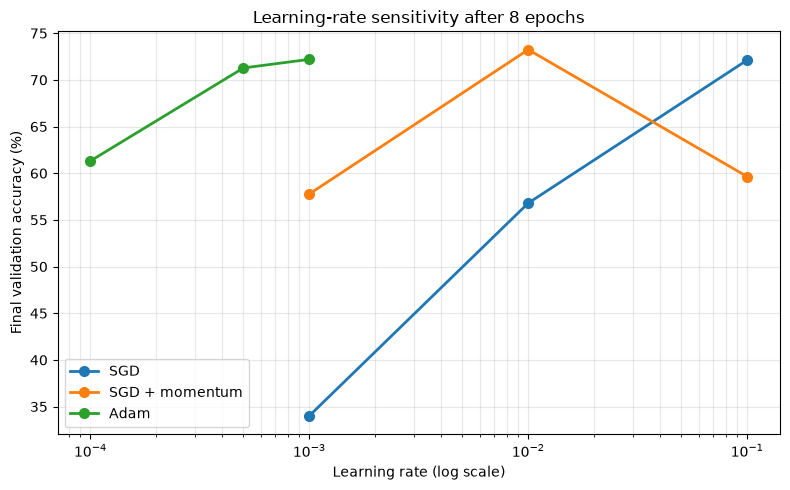

In [37]:
fig, axis = plt.subplots(figsize=(8, 5))
for optimizer_name in TASK2C_LEARNING_RATES:
    rows = task2c_results[task2c_results["optimizer"] == optimizer_name].sort_values(
        "learning rate"
    )
    axis.plot(
        rows["learning rate"], rows["final validation accuracy (%)"],
        marker="o", linewidth=2, markersize=7, label=optimizer_name,
    )
axis.set_xscale("log")
axis.set(
    xlabel="Learning rate (log scale)",
    ylabel="Final validation accuracy (%)",
    title=f"Learning-rate sensitivity after {TASK2C_EPOCHS} epochs",
)
axis.grid(True, which="both", alpha=0.3)
axis.legend()
fig.tight_layout()
plt.show()

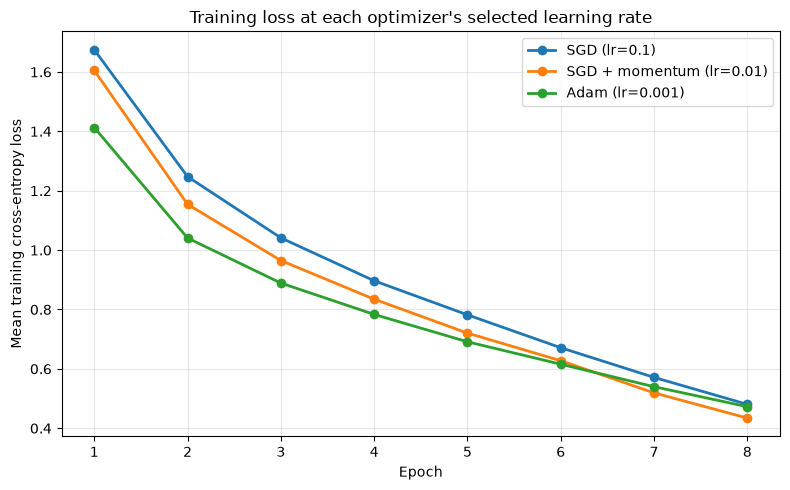

In [38]:
fig, axis = plt.subplots(figsize=(8, 5))
for optimizer_name, best_rate in task2c_best_rates.items():
    history = task2c_histories[(optimizer_name, best_rate)]
    axis.plot(
        history["epoch"], history["training loss"], marker="o", linewidth=2,
        label=f"{optimizer_name} (lr={best_rate:g})",
    )
axis.set(
    xlabel="Epoch", ylabel="Mean training cross-entropy loss",
    title="Training loss at each optimizer's selected learning rate",
)
axis.set_xticks(range(1, TASK2C_EPOCHS + 1))
axis.grid(alpha=0.3)
axis.legend()
fig.tight_layout()
plt.show()

Plain SGD is the most sensitive to learning rate: validation accuracy climbs from 34.02% at $10^{-3}$ to 72.12% at the selected $10^{-1}$ (a 38.10-point range). Loss falls at every setting, so low rates mean slow learning within eight epochs, not divergence.

Momentum SGD selects $10^{-2}$ and gets the best final validation accuracy (73.24%) and lowest final training loss (0.4342). Its accuracy range is 15.46 points. At $10^{-1}$ it fluctuates, peaking at 61.22% in epoch 4 and ending at 59.64%, which fits an overly aggressive rate with accumulated velocity.

Adam ranges from 61.32% at $10^{-4}$ to 72.20% at the selected $10^{-3}$ (10.88 points) and has the lowest loss after epoch 1, reaching 0.4726 by epoch 8. It looks least sensitive, but its sweep spans a factor of 10 versus 100 for SGD, so the ranges are not standardized robustness measures.

The selected accuracies (72.12%, 73.24%, 72.20%) are too close for a single-seed run to establish a general ranking. The results support momentum's faster progress and Adam's adaptive early progress for this CNN and these settings only.

# Task 3: Regularization and residual connections

## Task 3(a): Regularization on 5,000 training images

Regularization aims to reduce the gap between training and unseen-data performance. The accuracy gap is $G_{\mathrm{acc}}=A_{\mathrm{train}}-A_{\mathrm{validation}}$, in percentage points. A large positive gap can signal overfitting, but a small gap doesn't prove good generalization if both accuracies are low. All final accuracies are measured with `model.eval()` on plain normalized images, so dropout is off, batch normalization uses running statistics, and neither split is augmented or mixed.

Every condition uses batch normalization after each convolution. The seven conditions isolate weight decay (discourages large weights), dropout (masks hidden activations), geometric augmentation (flip and crop), cutout (removes a spatial region), mixup (interpolates inputs and targets), and their combination. Because these effects can interact, the combined condition is not assumed to be best.

### Controlled protocol and hyperparameters

The fixed 5,000-image training subset is the first 5,000 indices of the seeded random permutation of the 45k training images. It is not the validation set. All seven runs use the full 5,000-image validation partition, the same initial weights and shuffled minibatch order, batch size 128, 30 epochs, cross-entropy, and SGD with momentum 0.9 at learning rate 0.01 with no schedule. This is a single-seed comparison.

Weight decay is $5\times10^{-4}$, applied to convolutional and linear weights only. Dropout uses $p=0.5$ after the hidden fully connected ReLU. Flip+crop uses a horizontal-flip probability of 0.5 and a $32\times32$ crop after four-pixel reflection padding. Manual cutout masks a clipped $16\times16$ square after normalization and fills it with zero, which is the normalized training mean. Manual mixup draws one $\lambda\sim\operatorname{Beta}(0.2,0.2)$ per minibatch, without forcing $\lambda\geq0.5$, and optimizes $\lambda\,\mathrm{CE}(\tilde x,y_a)+(1-\lambda)\,\mathrm{CE}(\tilde x,y_b)$. In the combined condition the order is flip/crop, normalization, cutout, then mixup. The test set is not used.

In [39]:
TASK3A_TRAIN_SIZE = 5_000
task3a_train_indices = train_indices[:TASK3A_TRAIN_SIZE]
task3a_eval_dataset = Subset(normalized_dataset, task3a_train_indices)
task3a_eval_loader = DataLoader(task3a_eval_dataset, batch_size=128, shuffle=False, num_workers=num_workers, pin_memory=pin_memory)
task3a_class_counts = np.bincount(np.asarray(raw_dataset.targets)[task3a_train_indices], minlength=10)
assert len(task3a_train_indices) == TASK3A_TRAIN_SIZE
assert set(task3a_train_indices).issubset(set(train_indices))
assert set(task3a_train_indices).isdisjoint(val_indices)
pd.DataFrame({"training examples": task3a_class_counts}, index=raw_dataset.classes).T

,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
training examples,530,483,478,478,493,497,517,518,511,495


In [40]:
class ManualCutout:
    """Mask one clipped square in a normalized CHW tensor."""
    def __init__(self, size=16, fill=0.0):
        if size <= 0:
            raise ValueError("Cutout size must be positive")
        self.size, self.fill = size, fill

    def __call__(self, image):
        if image.ndim != 3:
            raise ValueError("Cutout expects a CHW tensor")
        _, height, width = image.shape
        center_y = torch.randint(height, (1,)).item()
        center_x = torch.randint(width, (1,)).item()
        half = self.size // 2
        top, bottom = max(0, center_y - half), min(height, center_y + self.size - half)
        left, right = max(0, center_x - half), min(width, center_x + self.size - half)
        result = image.clone()
        result[:, top:bottom, left:right] = self.fill
        return result

def manual_mixup(images, targets, alpha, beta_rng, permutation_generator):
    if alpha <= 0:
        raise ValueError("Mixup alpha must be positive")
    mixing_weight = float(beta_rng.beta(alpha, alpha))
    permutation = torch.randperm(images.shape[0], generator=permutation_generator).to(images.device)
    mixed_images = mixing_weight * images + (1.0 - mixing_weight) * images[permutation]
    return mixed_images, targets, targets[permutation], mixing_weight

cutout_shape_check = ManualCutout()(torch.ones(3, 32, 32))
assert cutout_shape_check.shape == (3, 32, 32) and cutout_shape_check.dtype == torch.float32
assert (cutout_shape_check == 0).any() and (cutout_shape_check == 1).any()
print("Manual cutout and mixup defined; cutout checks passed.")

Manual cutout and mixup defined; cutout checks passed.


In [41]:
TASK3A_CUTOUT_SIZE = 16
TASK3A_MIXUP_ALPHA = 0.2

def make_task3a_transform(use_geometric=False, use_cutout=False):
    operations = []
    if use_geometric:
        operations += [transforms.RandomCrop(32, padding=4, padding_mode="reflect"), transforms.RandomHorizontalFlip(0.5)]
    operations += [transforms.ToTensor(), normalization]
    if use_cutout:
        operations.append(ManualCutout(TASK3A_CUTOUT_SIZE, 0.0))
    return transforms.Compose(operations)

def make_task3a_training_loader(use_geometric=False, use_cutout=False):
    dataset = CIFAR10(root=DATA_ROOT, train=True, download=False, transform=make_task3a_transform(use_geometric, use_cutout))
    return DataLoader(Subset(dataset, task3a_train_indices), batch_size=128, shuffle=True, num_workers=num_workers, pin_memory=pin_memory, generator=torch.Generator().manual_seed(SEED))

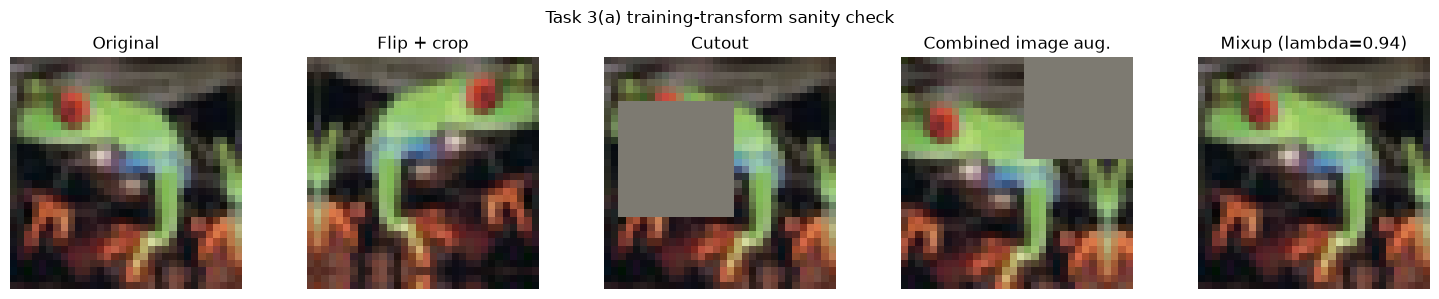

In [42]:
seed_everything(SEED)
preview_index = task3a_train_indices[0]
preview_specs = {"Original": (False, False), "Flip + crop": (True, False), "Cutout": (False, True), "Combined image aug.": (True, True)}
preview_images = {}
for name, spec in preview_specs.items():
    dataset = CIFAR10(root=DATA_ROOT, train=True, download=False, transform=make_task3a_transform(*spec))
    preview_images[name] = dataset[preview_index][0]
preview_batch = torch.stack([preview_images["Original"], preview_images["Flip + crop"]])
mixed_preview, _, _, preview_lambda = manual_mixup(preview_batch, torch.tensor([0, 1]), TASK3A_MIXUP_ALPHA, np.random.default_rng(SEED), torch.Generator().manual_seed(SEED))
preview_images[f"Mixup (lambda={preview_lambda:.2f})"] = mixed_preview[0]
fig, axes = plt.subplots(1, len(preview_images), figsize=(15, 3))
for axis, (name, image_tensor) in zip(axes, preview_images.items()):
    display_image = (image_tensor * channel_std[:, None, None] + channel_mean[:, None, None]).clamp(0, 1)
    axis.imshow(display_image.permute(1, 2, 0))
    axis.set_title(name)
    axis.axis("off")
fig.suptitle("Task 3(a) training-transform sanity check")
fig.tight_layout()
plt.show()

In [43]:
class RegularizedSmallCNN(nn.Module):
    def __init__(self, use_dropout=False):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 8 * 8, 128), nn.ReLU(),
            nn.Dropout(0.5) if use_dropout else nn.Identity(), nn.Linear(128, 10),
        )

    def forward(self, inputs):
        return self.classifier(self.features(inputs))

seed_everything(SEED)
task3a_base_model = RegularizedSmallCNN()
task3a_initial_state = copy.deepcopy(task3a_base_model.state_dict())
with torch.no_grad():
    task3a_shape_check = task3a_base_model(torch.zeros(2, 3, 32, 32))
assert task3a_shape_check.shape == (2, 10)
assert sum(isinstance(m, nn.BatchNorm2d) for m in task3a_base_model.modules()) == 2
print(f"Output shape: {tuple(task3a_shape_check.shape)}")
print(f"Trainable parameters: {sum(p.numel() for p in task3a_base_model.parameters()):,}")

Output shape: (2, 10)
Trainable parameters: 545,290


In [44]:
TASK3A_EPOCHS = 30
TASK3A_LEARNING_RATE = 0.01
TASK3A_MOMENTUM = 0.9
TASK3A_WEIGHT_DECAY = 5e-4

task3a_conditions = {
    "Baseline": dict(weight_decay=False, dropout=False, geometric=False, cutout=False, mixup=False),
    "Weight decay": dict(weight_decay=True, dropout=False, geometric=False, cutout=False, mixup=False),
    "Dropout": dict(weight_decay=False, dropout=True, geometric=False, cutout=False, mixup=False),
    "Flip + crop": dict(weight_decay=False, dropout=False, geometric=True, cutout=False, mixup=False),
    "Cutout": dict(weight_decay=False, dropout=False, geometric=False, cutout=True, mixup=False),
    "Mixup": dict(weight_decay=False, dropout=False, geometric=False, cutout=False, mixup=True),
    "All combined": dict(weight_decay=True, dropout=True, geometric=True, cutout=True, mixup=True),
}
pd.DataFrame(task3a_conditions).T

,weight_decay,dropout,geometric,cutout,mixup
Baseline,False,False,False,False,False
Weight decay,True,False,False,False,False
Dropout,False,True,False,False,False
Flip + crop,False,False,True,False,False
Cutout,False,False,False,True,False
Mixup,False,False,False,False,True
All combined,True,True,True,True,True


In [45]:
def build_task3a_optimizer(model, use_weight_decay):
    decay_parameters = [p for p in model.parameters() if p.ndim > 1]
    no_decay_parameters = [p for p in model.parameters() if p.ndim <= 1]
    decay = TASK3A_WEIGHT_DECAY if use_weight_decay else 0.0
    return torch.optim.SGD(
        [{"params": decay_parameters, "weight_decay": decay}, {"params": no_decay_parameters, "weight_decay": 0.0}],
        lr=TASK3A_LEARNING_RATE, momentum=TASK3A_MOMENTUM,
    )

@torch.no_grad()
def evaluate_task3a(model, loader):
    model.eval()
    loss_sum = correct = total = 0
    for batch_images, batch_targets in loader:
        batch_images = batch_images.to(device, non_blocking=pin_memory)
        batch_targets = batch_targets.to(device, non_blocking=pin_memory)
        logits = model(batch_images)
        loss_sum += F.cross_entropy(logits, batch_targets, reduction="sum").item()
        correct += (logits.argmax(1) == batch_targets).sum().item()
        total += batch_targets.shape[0]
    return loss_sum / total, 100.0 * correct / total

def train_task3a_condition(condition_name, settings):
    seed_everything(SEED)
    model = RegularizedSmallCNN(settings["dropout"])
    model.load_state_dict(task3a_initial_state)
    model = model.to(device)
    optimizer = build_task3a_optimizer(model, settings["weight_decay"])
    training_loader = make_task3a_training_loader(settings["geometric"], settings["cutout"])
    beta_rng = np.random.default_rng(SEED)
    permutation_generator = torch.Generator().manual_seed(SEED + 1)
    history, start_time = [], time.perf_counter()

    for epoch in range(1, TASK3A_EPOCHS + 1):
        model.train()
        optimization_loss_sum = sample_count = 0
        for batch_images, batch_targets in training_loader:
            batch_images = batch_images.to(device, non_blocking=pin_memory)
            batch_targets = batch_targets.to(device, non_blocking=pin_memory)
            optimizer.zero_grad(set_to_none=True)
            if settings["mixup"]:
                inputs, targets_a, targets_b, lam = manual_mixup(batch_images, batch_targets, TASK3A_MIXUP_ALPHA, beta_rng, permutation_generator)
                logits = model(inputs)
                loss = lam * F.cross_entropy(logits, targets_a) + (1.0 - lam) * F.cross_entropy(logits, targets_b)
            else:
                logits = model(batch_images)
                loss = F.cross_entropy(logits, batch_targets)
            if not torch.isfinite(loss):
                raise RuntimeError(f"Non-finite loss in {condition_name}")
            loss.backward()
            optimizer.step()
            batch_size = batch_targets.shape[0]
            optimization_loss_sum += loss.detach().item() * batch_size
            sample_count += batch_size

        train_loss, train_accuracy = evaluate_task3a(model, task3a_eval_loader)
        validation_loss, validation_accuracy = evaluate_task3a(model, val_loader)
        history.append({
            "epoch": epoch, "optimization loss": optimization_loss_sum / sample_count,
            "train evaluation loss": train_loss, "validation loss": validation_loss,
            "train accuracy (%)": train_accuracy, "validation accuracy (%)": validation_accuracy,
            "elapsed time (s)": time.perf_counter() - start_time,
        })
        if epoch == 1 or epoch % 5 == 0:
            print(f"{condition_name:14s} | epoch {epoch:02d}/{TASK3A_EPOCHS}: train={train_accuracy:.2f}%, val={validation_accuracy:.2f}%, gap={train_accuracy-validation_accuracy:.2f} pp")
    return pd.DataFrame(history)

In [46]:
task3a_histories = {}
task3a_experiment_start = time.perf_counter()
for condition_name, settings in task3a_conditions.items():
    print(f"\nStarting {condition_name}")
    task3a_histories[condition_name] = train_task3a_condition(condition_name, settings)
task3a_total_time = time.perf_counter() - task3a_experiment_start
print(f"\nCompleted all seven conditions in {task3a_total_time / 60:.2f} minutes.")


Starting Baseline


Baseline       | epoch 01/30: train=39.92%, val=38.48%, gap=1.44 pp


Baseline       | epoch 05/30: train=61.10%, val=47.80%, gap=13.30 pp


Baseline       | epoch 10/30: train=81.74%, val=55.22%, gap=26.52 pp


Baseline       | epoch 15/30: train=92.48%, val=56.40%, gap=36.08 pp


...

All combined   | epoch 10/30: train=45.68%, val=43.32%, gap=2.36 pp


All combined   | epoch 15/30: train=51.20%, val=48.64%, gap=2.56 pp


All combined   | epoch 20/30: train=51.82%, val=48.90%, gap=2.92 pp


All combined   | epoch 25/30: train=56.18%, val=52.56%, gap=3.62 pp


All combined   | epoch 30/30: train=57.78%, val=54.02%, gap=3.76 pp

Completed all seven conditions in 3.31 minutes.


In [47]:
task3a_rows = []
for condition_name, history in task3a_histories.items():
    final = history.iloc[-1]
    task3a_rows.append({
        "condition": condition_name,
        "train accuracy (%)": final["train accuracy (%)"],
        "validation accuracy (%)": final["validation accuracy (%)"],
        "train - validation gap (pp)": final["train accuracy (%)"] - final["validation accuracy (%)"],
        "train evaluation loss": final["train evaluation loss"],
        "validation loss": final["validation loss"],
        "runtime (s)": final["elapsed time (s)"],
    })
task3a_results = pd.DataFrame(task3a_rows).set_index("condition")
task3a_results

,train accuracy (%),validation accuracy (%),train - validation gap (pp),train evaluation loss,validation loss,runtime (s)
condition,,,,,,
Baseline,100.00,60.82,39.18,0.005347,2.035472,25.902495
Weight decay,100.00,61.64,38.36,0.008060,1.891373,26.048282
Dropout,85.10,59.62,25.48,0.491594,1.219510,26.273560
Flip + crop,76.06,65.64,10.42,0.662988,1.036591,31.190740
Cutout,98.36,60.56,37.80,0.090414,1.483645,26.798109
Mixup,99.50,57.24,42.26,0.135285,1.375988,28.184501
All combined,57.78,54.02,3.76,1.239724,1.324639,32.312436


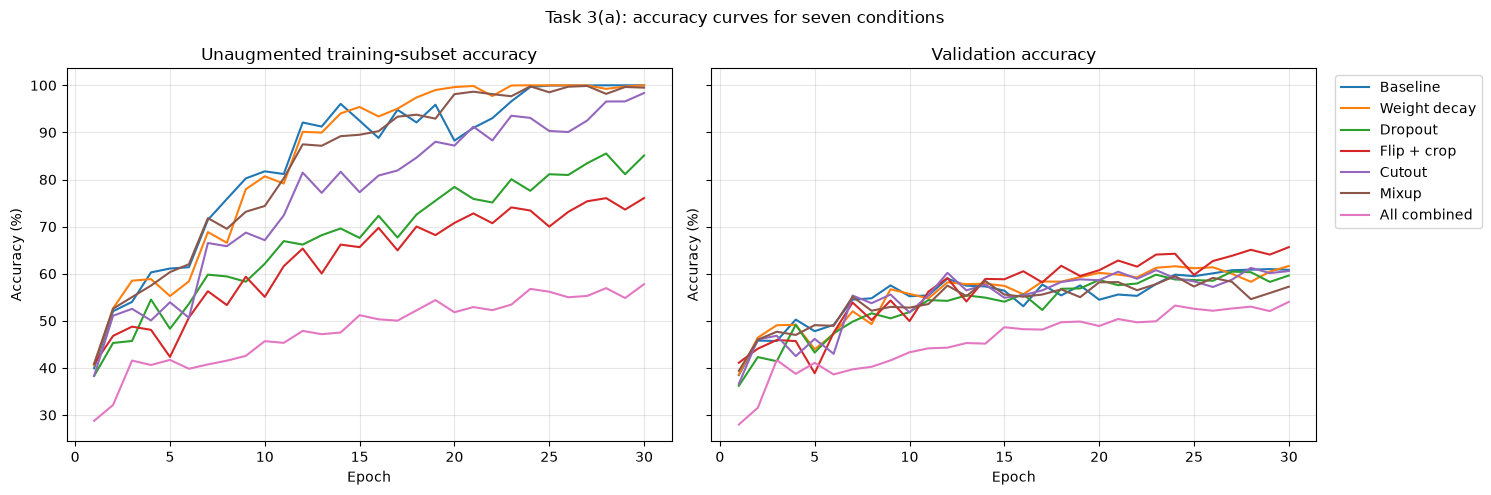

In [48]:
task3a_colors = dict(zip(task3a_conditions, plt.cm.tab10.colors[:len(task3a_conditions)]))
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for condition_name, history in task3a_histories.items():
    color = task3a_colors[condition_name]
    axes[0].plot(history["epoch"], history["train accuracy (%)"], color=color, label=condition_name)
    axes[1].plot(history["epoch"], history["validation accuracy (%)"], color=color, label=condition_name)
axes[0].set_title("Unaugmented training-subset accuracy")
axes[1].set_title("Validation accuracy")
for axis in axes:
    axis.set(xlabel="Epoch", ylabel="Accuracy (%)")
    axis.grid(alpha=0.3)
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("Task 3(a): accuracy curves for seven conditions")
fig.tight_layout()
plt.show()

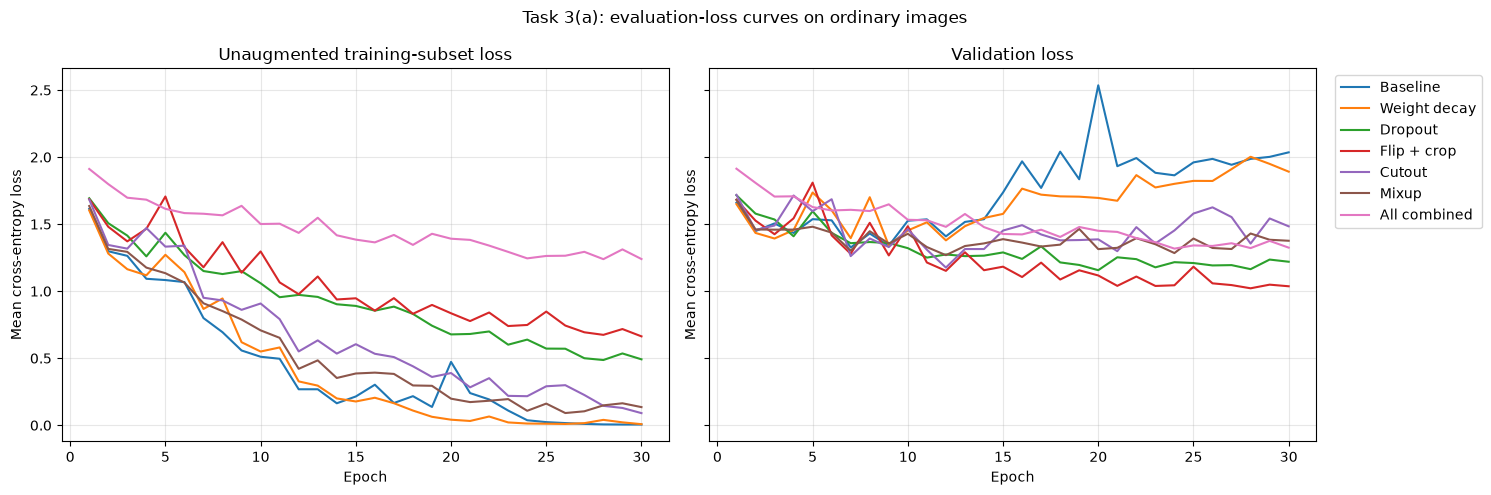

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for condition_name, history in task3a_histories.items():
    color = task3a_colors[condition_name]
    axes[0].plot(history["epoch"], history["train evaluation loss"], color=color, label=condition_name)
    axes[1].plot(history["epoch"], history["validation loss"], color=color, label=condition_name)
axes[0].set_title("Unaugmented training-subset loss")
axes[1].set_title("Validation loss")
for axis in axes:
    axis.set(xlabel="Epoch", ylabel="Mean cross-entropy loss")
    axis.grid(alpha=0.3)
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("Task 3(a): evaluation-loss curves on ordinary images")
fig.tight_layout()
plt.show()

The baseline hits 100.00% training accuracy but only 60.82% validation accuracy (a 39.18-point gap). Training loss nears zero while validation loss rises to 2.0355, which is direct evidence of memorization on the 5,000-image subset. Weight decay also reaches 100.00% training accuracy, with a small validation gain to 61.64% and validation loss of 1.8914, but its 38.36-point gap shows it doesn't prevent substantial overfitting.

Dropout cuts training accuracy to 85.10% and the gap to 25.48 points, but validation accuracy (59.62%) is 1.20 points below baseline, so the weaker fit doesn't improve final accuracy. Cutout resembles the baseline (98.36% training, 60.56% validation, 37.80-point gap), so a single $16\times16$ mask adds little here.

Flip+crop is the best: 76.06% training, 65.64% validation, a 10.42-point gap, and the lowest validation loss at 1.0366. Training accuracy rises slowly while validation keeps improving, consistent with learning invariance to plausible translations and reflections instead of memorizing pixels. Mixup reaches 99.50% training but only 57.24% validation, the largest gap at 42.26 points. It is implemented correctly but doesn't help with $\alpha=0.2$, the fixed learning rate, and 30 epochs.

All combined has the smallest gap (3.76 points) but the lowest accuracies, 57.78% training and 54.02% validation. Its training evaluation loss of 1.2397 and slow accuracy growth point to underfitting from stacking strong regularizers, so the gap can't be read alone.

Overall, flip+crop generalizes best in this single-seed comparison, weight decay helps modestly, and the other individual choices don't beat the baseline at the final epoch. These conclusions apply only to the recorded hyperparameters and subset; no test data were used.

## Task 3(b): CIFAR-style plain and residual networks

A deeper plain network can have higher training error than a shallower one even though it has greater representational capacity. This is the degradation problem: learning useful transformations, including identity mappings, becomes harder as an ordinary stack grows deeper. A residual block makes an identity mapping directly available:

$$H_{\mathrm{plain}}(x)=\phi(F(x)), \qquad H_{\mathrm{residual}}(x)=\phi(F(x)+S(x)).$$

When shapes match, $S(x)=x$. Ignoring the final activation, $y=x+F(x)$ gives $\partial L/\partial x=(\partial L/\partial y)(I+\partial F/\partial x)$, so the shortcut contributes a direct identity term to backward flow. This helps optimization but does not guarantee that every residual model always has lower loss.

The required depth counts the stem convolution, two convolutions in every block, and the classifier: $D=1+3n\times2+1=6n+2$. Thus depths 8, 20 and 56 use $n=1,3,9$ blocks per stage. The three stages have 16, 32 and 64 channels at spatial resolutions $32\times32$, $16\times16$ and $8\times8$, followed by global average pooling and a 64-to-10 classifier.

### Architecture and training controls

Both families use one post-activation basic block with the main path `Conv-BN-ReLU-Conv-BN` and a final ReLU. Only the residual version adds a shortcut before that ReLU. At stage transitions, the shortcut is the parameter-free CIFAR Option A (stride-2 subsampling plus zero-padding of the extra channels), so matched plain and residual networks have identical learned parameters and differ only in the shortcut.

Convolutional weights use Kaiming-normal initialization (`mode='fan_out'`, ReLU gain), and batch-norm scales and biases start at one and zero. The final linear classifier uses Kaiming-normal (`mode='fan_in'`, linear gain), since no ReLU follows its logits. Both families follow the same convention.

All six models train on the full 45,000-image training partition for 10 epochs, batch size 128, with the same normalized inputs, minibatch order, and cross-entropy loss. Initial parameters are shared within each depth pair. The optimizer is SGD with learning rate 0.1 and momentum 0.9, with no augmentation, weight decay, dropout, or schedule, which keeps the focus on optimization. Training loss is the sample-weighted mean, and validation and test data are not used.

In [50]:
class CIFARBasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride, use_shortcut):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.use_shortcut = use_shortcut
        self.stride = stride
        self.channel_increase = out_channels - in_channels
        assert self.channel_increase >= 0

    def option_a_shortcut(self, inputs):
        shortcut = inputs[:, :, ::self.stride, ::self.stride]
        if self.channel_increase:
            left = self.channel_increase // 2
            right = self.channel_increase - left
            shortcut = F.pad(shortcut, (0, 0, 0, 0, left, right))
        return shortcut

    def forward(self, inputs):
        output = self.relu(self.bn1(self.conv1(inputs)))
        output = self.bn2(self.conv2(output))
        if self.use_shortcut:
            output = output + self.option_a_shortcut(inputs)
        return self.relu(output)

In [51]:
class CIFARDepthNetwork(nn.Module):
    def __init__(self, depth, use_shortcuts):
        super().__init__()
        if (depth - 2) % 6 != 0:
            raise ValueError("Depth must have the form 6n + 2")
        blocks_per_stage = (depth - 2) // 6
        self.depth = depth
        self.blocks_per_stage = blocks_per_stage
        self.use_shortcuts = use_shortcuts
        self.stem = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1, bias=False),
            nn.BatchNorm2d(16), nn.ReLU(inplace=True),
        )
        self.stage1 = self._make_stage(16, 16, blocks_per_stage, first_stride=1)
        self.stage2 = self._make_stage(16, 32, blocks_per_stage, first_stride=2)
        self.stage3 = self._make_stage(32, 64, blocks_per_stage, first_stride=2)
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Linear(64, 10)
        self.apply(self._initialize_module)

    def _make_stage(self, in_channels, out_channels, block_count, first_stride):
        blocks = [CIFARBasicBlock(in_channels, out_channels, first_stride, self.use_shortcuts)]
        blocks += [CIFARBasicBlock(out_channels, out_channels, 1, self.use_shortcuts) for _ in range(1, block_count)]
        return nn.Sequential(*blocks)

    @staticmethod
    def _initialize_module(module):
        if isinstance(module, nn.Conv2d):
            nn.init.kaiming_normal_(module.weight, mode="fan_out", nonlinearity="relu")
        elif isinstance(module, nn.BatchNorm2d):
            nn.init.ones_(module.weight)
            nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Linear):
            nn.init.kaiming_normal_(module.weight, mode="fan_in", nonlinearity="linear")
            nn.init.zeros_(module.bias)

    def forward_features(self, inputs):
        stem = self.stem(inputs)
        stage1 = self.stage1(stem)
        stage2 = self.stage2(stage1)
        stage3 = self.stage3(stage2)
        return stem, stage1, stage2, stage3

    def forward(self, inputs):
        stage3 = self.forward_features(inputs)[-1]
        pooled = self.pool(stage3).flatten(1)
        return self.classifier(pooled)

In [52]:
TASK3B_DEPTHS = [8, 20, 56]
task3b_initial_states = {}
task3b_architecture_rows = []
for depth in TASK3B_DEPTHS:
    seed_everything(SEED + depth)
    plain_model = CIFARDepthNetwork(depth, use_shortcuts=False)
    task3b_initial_states[depth] = copy.deepcopy(plain_model.state_dict())
    for family, use_shortcuts in [("Plain", False), ("Residual", True)]:
        model = CIFARDepthNetwork(depth, use_shortcuts)
        model.load_state_dict(task3b_initial_states[depth])
        with torch.no_grad():
            feature_shapes = [tuple(t.shape) for t in model.forward_features(torch.zeros(2, 3, 32, 32))]
            output_shape = tuple(model(torch.zeros(2, 3, 32, 32)).shape)
        counted_depth = sum(isinstance(m, (nn.Conv2d, nn.Linear)) for m in model.modules())
        parameter_count = sum(p.numel() for p in model.parameters())
        assert counted_depth == depth and output_shape == (2, 10)
        assert feature_shapes == [(2, 16, 32, 32), (2, 16, 32, 32), (2, 32, 16, 16), (2, 64, 8, 8)]
        task3b_architecture_rows.append({
            "family": family, "depth": depth, "n": (depth - 2) // 6,
            "counted depth": counted_depth, "parameters": parameter_count,
            "logit shape": output_shape,
        })
task3b_architecture_table = pd.DataFrame(task3b_architecture_rows)
for depth in TASK3B_DEPTHS:
    pair = task3b_architecture_table[task3b_architecture_table["depth"] == depth]
    assert pair["parameters"].nunique() == 1
task3b_architecture_table

,family,depth,n,counted depth,parameters,logit shape
0,Plain,8,1,8,75290,"(2, 10)"
1,Residual,8,1,8,75290,"(2, 10)"
2,Plain,20,3,20,269722,"(2, 10)"
3,Residual,20,3,20,269722,"(2, 10)"
4,Plain,56,9,56,853018,"(2, 10)"
5,Residual,56,9,56,853018,"(2, 10)"


In [53]:
TASK3B_EPOCHS = 10
TASK3B_BATCH_SIZE = 128
TASK3B_LEARNING_RATE = 0.1
TASK3B_MOMENTUM = 0.9

def make_task3b_train_loader():
    return DataLoader(
        train_dataset, batch_size=TASK3B_BATCH_SIZE, shuffle=True,
        num_workers=num_workers, pin_memory=pin_memory,
        generator=torch.Generator().manual_seed(SEED),
    )

def train_task3b_model(family, depth, use_shortcuts):
    seed_everything(SEED)
    model = CIFARDepthNetwork(depth, use_shortcuts)
    model.load_state_dict(task3b_initial_states[depth])
    model = model.to(device)
    optimizer = torch.optim.SGD(
        model.parameters(), lr=TASK3B_LEARNING_RATE, momentum=TASK3B_MOMENTUM
    )
    training_loader = make_task3b_train_loader()
    history = []
    start_time = time.perf_counter()
    for epoch in range(1, TASK3B_EPOCHS + 1):
        model.train()
        loss_sum = 0.0
        sample_count = 0
        for batch_images, batch_targets in training_loader:
            batch_images = batch_images.to(device, non_blocking=pin_memory)
            batch_targets = batch_targets.to(device, non_blocking=pin_memory)
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(batch_images), batch_targets)
            if not torch.isfinite(loss):
                raise RuntimeError(f"Non-finite loss for {family}-{depth}")
            loss.backward()
            optimizer.step()
            batch_size = batch_targets.shape[0]
            loss_sum += loss.detach().item() * batch_size
            sample_count += batch_size
        mean_loss = loss_sum / sample_count
        history.append({
            "epoch": epoch, "training loss": mean_loss,
            "elapsed time (s)": time.perf_counter() - start_time,
        })
        print(f"{family:8s}-{depth:02d} | epoch {epoch:02d}/{TASK3B_EPOCHS}: loss={mean_loss:.4f}")
    return pd.DataFrame(history)

In [54]:
task3b_histories = {}
task3b_experiment_start = time.perf_counter()
for depth in TASK3B_DEPTHS:
    for family, use_shortcuts in [("Plain", False), ("Residual", True)]:
        print(f"\nStarting {family}-{depth}")
        task3b_histories[(family, depth)] = train_task3b_model(family, depth, use_shortcuts)
task3b_total_time = time.perf_counter() - task3b_experiment_start
print(f"\nCompleted all six models in {task3b_total_time / 60:.2f} minutes.")


Starting Plain-8


Plain   -08 | epoch 01/10: loss=1.4726


Plain   -08 | epoch 02/10: loss=1.0341


Plain   -08 | epoch 03/10: loss=0.8674


Plain   -08 | epoch 04/10: loss=0.7632


...

Residual-56 | epoch 06/10: loss=0.6947


Residual-56 | epoch 07/10: loss=0.6019


Residual-56 | epoch 08/10: loss=0.5191


Residual-56 | epoch 09/10: loss=0.4516


Residual-56 | epoch 10/10: loss=0.3913

Completed all six models in 9.96 minutes.


In [55]:
task3b_rows = []
for (family, depth), history in task3b_histories.items():
    parameters = task3b_architecture_table.query("family == @family and depth == @depth")["parameters"].iloc[0]
    task3b_rows.append({
        "family": family, "depth": depth, "parameters": parameters,
        "initial epoch loss": history["training loss"].iloc[0],
        "final training loss": history["training loss"].iloc[-1],
        "minimum training loss": history["training loss"].min(),
        "runtime (s)": history["elapsed time (s)"].iloc[-1],
    })
task3b_results = pd.DataFrame(task3b_rows).sort_values(["depth", "family"])
task3b_results

,family,depth,parameters,initial epoch loss,final training loss,minimum training loss,runtime (s)
0,Plain,8,75290,1.472564,0.459895,0.459895,40.422741
1,Residual,8,75290,1.540374,0.499886,0.499886,43.671713
2,Plain,20,269722,1.590932,0.408149,0.408149,74.571483
3,Residual,20,269722,1.456182,0.284895,0.284895,78.422355
4,Plain,56,853018,2.180117,1.442047,1.442047,174.520233
5,Residual,56,853018,2.191726,0.391340,0.391340,186.049842


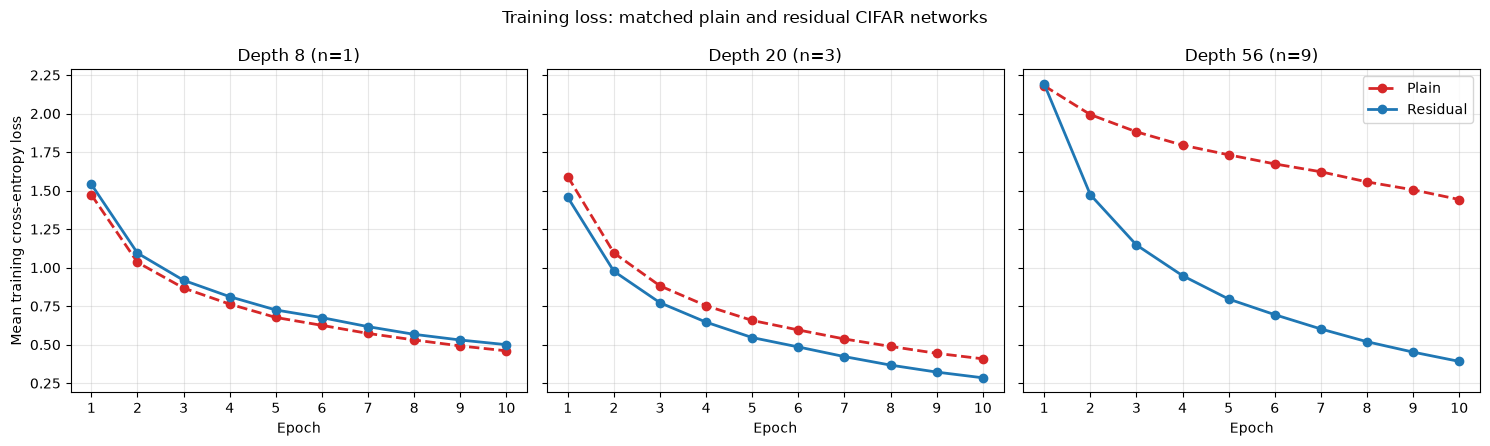

In [56]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
family_styles = {"Plain": ("tab:red", "--"), "Residual": ("tab:blue", "-")}
for axis, depth in zip(axes, TASK3B_DEPTHS):
    for family in ["Plain", "Residual"]:
        history = task3b_histories[(family, depth)]
        color, linestyle = family_styles[family]
        axis.plot(
            history["epoch"], history["training loss"], marker="o",
            color=color, linestyle=linestyle, linewidth=2, label=family,
        )
    axis.set_title(f"Depth {depth} (n={(depth - 2) // 6})")
    axis.set_xlabel("Epoch")
    axis.set_xticks(range(1, TASK3B_EPOCHS + 1))
    axis.grid(alpha=0.3)
axes[0].set_ylabel("Mean training cross-entropy loss")
axes[-1].legend()
fig.suptitle("Training loss: matched plain and residual CIFAR networks")
fig.tight_layout()
plt.show()

At depth 8, both families train smoothly and plain finishes slightly lower (0.4599 vs 0.4999 for residual), so a shortcut doesn't automatically help shallow networks. At depth 20, the residual curve is below plain from the first epoch and ends at 0.2849 versus 0.4081, a clear optimization advantage.

Depth 56 shows the largest gap. Plain falls only from 2.1801 to 1.4420, while residual drops from a similar 2.1917 to 0.3913. The plain-56 model trains worse than plain-8 and plain-20 despite more capacity. Because this is training loss, it reflects the degradation/optimization problem, not overfitting. The shortcut provides an identity path, eases identity-like transformations, and supplies the identity term in the backward derivative, consistent with the steeper decrease.

Depth still isn't uniformly beneficial: residual-20 ends lower than residual-56 within the 10-epoch budget, and the deeper model may need more training time or a different schedule. It nonetheless avoids the severe degradation of plain-56. Parameter counts match within each pair (75,290 at depth 8, 269,722 at depth 20, 853,018 at depth 56) and runtimes are similar, so the differences can be attributed to the parameter-free shortcut under this controlled setup.

# Task 4: Final CNN and ablation study

The final model is limited to 500,000 trainable parameters and 20 epochs. Architecture and hyperparameters are chosen on the validation split only. The test set must not influence any choice (architecture, optimizer, regularization, epoch, or checkpoint) and is instantiated and evaluated only after the validation-based choice is fixed.

The candidate is a depth-32 CIFAR network ($32=6(5)+2$) that keeps the three 16/32/64-channel stages, batch normalization, Kaiming initialization, parameter-free residual shortcuts, and global average pooling from Task 3(b). It uses the budget more fully than depth 20 while staying under 500k parameters. The full configuration adds reflection-padded random crop, horizontal flip, AdamW weight decay, and cosine learning-rate decay.

Four ablations each change one choice from the full candidate: remove shortcuts, remove augmentation, remove weight decay, or replace AdamW with momentum SGD. The final checkpoint is the configuration and epoch with the highest validation accuracy, with ties broken by the earlier epoch, then configuration order. The test set is then loaded once.

### Fixed training protocol

All runs use the full 45,000 training examples, the same copied initialization and seeded minibatch order, batch size 128, 20 epochs, and cross-entropy. The full candidate uses AdamW (learning rate $10^{-3}$, weight decay $5\times10^{-4}$ on convolutional/linear weights only) with cosine decay to $10^{-5}$. The SGD ablation uses learning rate 0.1, momentum 0.9, the same weight decay, and cosine decay to $10^{-4}$. Augmentation is a random $32\times32$ crop after four-pixel reflection padding plus a horizontal flip with probability 0.5. No test information is used.

In [57]:
TASK4_DEPTH = 32
TASK4_EPOCHS = 20
TASK4_BATCH_SIZE = 128
TASK4_WEIGHT_DECAY = 5e-4

task4_configurations = {
    "Full candidate": dict(shortcuts=True, augmentation=True, weight_decay=True, optimizer="AdamW"),
    "No shortcuts": dict(shortcuts=False, augmentation=True, weight_decay=True, optimizer="AdamW"),
    "No augmentation": dict(shortcuts=True, augmentation=False, weight_decay=True, optimizer="AdamW"),
    "No weight decay": dict(shortcuts=True, augmentation=True, weight_decay=False, optimizer="AdamW"),
    "SGD optimizer": dict(shortcuts=True, augmentation=True, weight_decay=True, optimizer="SGD"),
}
pd.DataFrame(task4_configurations).T

,shortcuts,augmentation,weight_decay,optimizer
Full candidate,True,True,True,AdamW
No shortcuts,False,True,True,AdamW
No augmentation,True,False,True,AdamW
No weight decay,True,True,False,AdamW
SGD optimizer,True,True,True,SGD


In [58]:
seed_everything(SEED + TASK4_DEPTH)
task4_initial_model = CIFARDepthNetwork(TASK4_DEPTH, use_shortcuts=True)
task4_initial_state = copy.deepcopy(task4_initial_model.state_dict())
TASK4_PARAMETER_COUNT = sum(p.numel() for p in task4_initial_model.parameters())
TASK4_COUNTED_DEPTH = sum(isinstance(m, (nn.Conv2d, nn.Linear)) for m in task4_initial_model.modules())
with torch.no_grad():
    task4_output_shape = tuple(task4_initial_model(torch.zeros(2, 3, 32, 32)).shape)
assert TASK4_PARAMETER_COUNT <= 500_000
assert TASK4_EPOCHS <= 20
assert TASK4_COUNTED_DEPTH == TASK4_DEPTH
assert task4_output_shape == (2, 10)
print(f"Depth: {TASK4_COUNTED_DEPTH}")
print(f"Trainable parameters: {TASK4_PARAMETER_COUNT:,} / 500,000")
print(f"Training epochs per configuration: {TASK4_EPOCHS} / 20")
print(f"Output shape: {task4_output_shape}")

Depth: 32
Trainable parameters: 464,154 / 500,000
Training epochs per configuration: 20 / 20
Output shape: (2, 10)


In [59]:
task4_augmented_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4, padding_mode="reflect"),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    normalization,
])

def make_task4_train_loader(use_augmentation):
    if use_augmentation:
        dataset = CIFAR10(root=DATA_ROOT, train=True, download=False, transform=task4_augmented_transform)
        training_data = Subset(dataset, train_indices)
    else:
        training_data = train_dataset
    return DataLoader(
        training_data, batch_size=TASK4_BATCH_SIZE, shuffle=True,
        num_workers=num_workers, pin_memory=pin_memory,
        generator=torch.Generator().manual_seed(SEED),
    )

def split_decay_parameters(model):
    decay = [p for p in model.parameters() if p.ndim > 1]
    no_decay = [p for p in model.parameters() if p.ndim <= 1]
    return decay, no_decay

def build_task4_optimizer_and_scheduler(model, configuration):
    decay_parameters, no_decay_parameters = split_decay_parameters(model)
    decay = TASK4_WEIGHT_DECAY if configuration["weight_decay"] else 0.0
    parameter_groups = [
        {"params": decay_parameters, "weight_decay": decay},
        {"params": no_decay_parameters, "weight_decay": 0.0},
    ]
    if configuration["optimizer"] == "AdamW":
        optimizer = torch.optim.AdamW(parameter_groups, lr=1e-3)
        minimum_lr = 1e-5
    else:
        optimizer = torch.optim.SGD(parameter_groups, lr=0.1, momentum=0.9)
        minimum_lr = 1e-4
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=TASK4_EPOCHS, eta_min=minimum_lr
    )
    return optimizer, scheduler

In [60]:
def train_task4_configuration(configuration_name, configuration):
    seed_everything(SEED)
    model = CIFARDepthNetwork(TASK4_DEPTH, configuration["shortcuts"])
    model.load_state_dict(task4_initial_state)
    model = model.to(device)
    optimizer, scheduler = build_task4_optimizer_and_scheduler(model, configuration)
    training_loader = make_task4_train_loader(configuration["augmentation"])
    history = []
    best_validation_accuracy = -float("inf")
    best_epoch = None
    best_state = None
    start_time = time.perf_counter()

    for epoch in range(1, TASK4_EPOCHS + 1):
        model.train()
        loss_sum = 0.0
        sample_count = 0
        learning_rate = optimizer.param_groups[0]["lr"]
        for batch_images, batch_targets in training_loader:
            batch_images = batch_images.to(device, non_blocking=pin_memory)
            batch_targets = batch_targets.to(device, non_blocking=pin_memory)
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(batch_images), batch_targets)
            if not torch.isfinite(loss):
                raise RuntimeError(f"Non-finite loss in {configuration_name}")
            loss.backward()
            optimizer.step()
            batch_size = batch_targets.shape[0]
            loss_sum += loss.detach().item() * batch_size
            sample_count += batch_size
        validation_loss, validation_accuracy = evaluate_task3a(model, val_loader)
        history.append({
            "epoch": epoch, "training loss": loss_sum / sample_count,
            "validation loss": validation_loss,
            "validation accuracy (%)": validation_accuracy,
            "learning rate": learning_rate,
            "elapsed time (s)": time.perf_counter() - start_time,
        })
        if validation_accuracy > best_validation_accuracy:
            best_validation_accuracy = validation_accuracy
            best_epoch = epoch
            best_state = {name: tensor.detach().cpu().clone() for name, tensor in model.state_dict().items()}
        scheduler.step()
        print(
            f"{configuration_name:16s} | epoch {epoch:02d}/{TASK4_EPOCHS}: "
            f"loss={loss_sum/sample_count:.4f}, val={validation_accuracy:.2f}%, lr={learning_rate:.6f}"
        )
    return pd.DataFrame(history), best_state, best_epoch, best_validation_accuracy

In [61]:
task4_histories = {}
task4_best_states = {}
task4_selection_records = []
task4_experiment_start = time.perf_counter()
for configuration_name, configuration in task4_configurations.items():
    print(f"\nStarting {configuration_name}")
    history, best_state, best_epoch, best_accuracy = train_task4_configuration(
        configuration_name, configuration
    )
    task4_histories[configuration_name] = history
    task4_best_states[configuration_name] = best_state
    task4_selection_records.append({
        "configuration": configuration_name,
        "best validation accuracy (%)": best_accuracy,
        "best epoch": best_epoch,
        "final validation accuracy (%)": history["validation accuracy (%)"].iloc[-1],
        "final training loss": history["training loss"].iloc[-1],
        "runtime (s)": history["elapsed time (s)"].iloc[-1],
    })
task4_total_time = time.perf_counter() - task4_experiment_start
print(f"\nCompleted all five validation runs in {task4_total_time / 60:.2f} minutes.")


Starting Full candidate


Full candidate   | epoch 01/20: loss=1.4675, val=53.98%, lr=0.001000


Full candidate   | epoch 02/20: loss=1.0825, val=66.32%, lr=0.000994


Full candidate   | epoch 03/20: loss=0.9035, val=70.76%, lr=0.000976


Full candidate   | epoch 04/20: loss=0.7863, val=69.42%, lr=0.000946


...

SGD optimizer    | epoch 16/20: loss=0.3144, val=86.64%, lr=0.014730


SGD optimizer    | epoch 17/20: loss=0.2789, val=88.04%, lr=0.009640


SGD optimizer    | epoch 18/20: loss=0.2496, val=88.50%, lr=0.005544


SGD optimizer    | epoch 19/20: loss=0.2298, val=89.14%, lr=0.002545


SGD optimizer    | epoch 20/20: loss=0.2183, val=89.12%, lr=0.000715

Completed all five validation runs in 21.99 minutes.


In [62]:
task4_ablation_results = pd.DataFrame(task4_selection_records)
task4_ablation_results["validation change vs full (pp)"] = (
    task4_ablation_results["best validation accuracy (%)"]
    - task4_ablation_results.loc[
        task4_ablation_results["configuration"] == "Full candidate",
        "best validation accuracy (%)",
    ].iloc[0]
)
task4_ablation_results

,configuration,best validation accuracy (%),best epoch,final validation accuracy (%),final training loss,runtime (s),validation change vs full (pp)
0,Full candidate,87.58,20,87.58,0.290788,274.197484,0.00
1,No shortcuts,79.28,18,79.10,0.577852,259.935961,-8.30
2,No augmentation,79.20,16,78.94,0.003567,243.141186,-8.38
3,No weight decay,87.32,20,87.32,0.290807,272.727768,-0.26
4,SGD optimizer,89.14,19,89.12,0.218285,267.813816,1.56


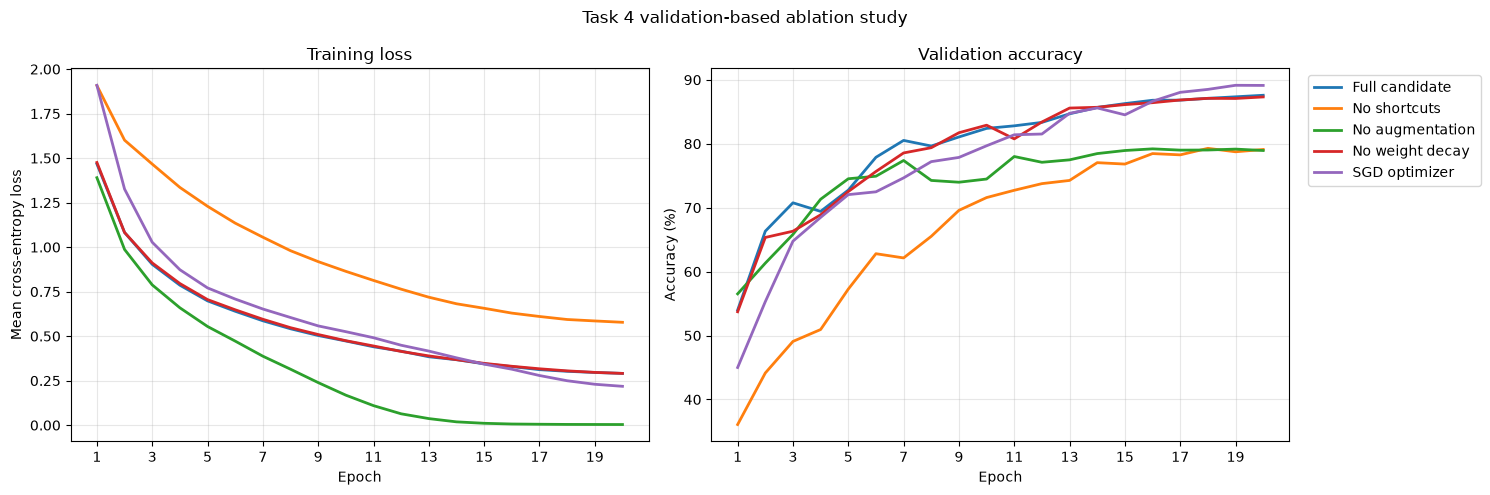

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for configuration_name, history in task4_histories.items():
    axes[0].plot(history["epoch"], history["training loss"], linewidth=2, label=configuration_name)
    axes[1].plot(history["epoch"], history["validation accuracy (%)"], linewidth=2, label=configuration_name)
axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Mean cross-entropy loss")
axes[1].set(title="Validation accuracy", xlabel="Epoch", ylabel="Accuracy (%)")
for axis in axes:
    axis.set_xticks(range(1, TASK4_EPOCHS + 1, 2))
    axis.grid(alpha=0.3)
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("Task 4 validation-based ablation study")
fig.tight_layout()
plt.show()

### Final validation-based selection and one-time test evaluation

The next cell applies the declared selection rule to the completed validation table. The test dataset has not been constructed in any preceding code cell. The selected configuration and its best-validation checkpoint are fixed first; only then is `CIFAR10(train=False)` instantiated and evaluated in one pass. No decision is changed after observing the test result.

In [64]:
task4_selection_order = {name: index for index, name in enumerate(task4_configurations)}
task4_ranked = task4_ablation_results.copy()
task4_ranked["configuration order"] = task4_ranked["configuration"].map(task4_selection_order)
task4_ranked = task4_ranked.sort_values(
    ["best validation accuracy (%)", "best epoch", "configuration order"],
    ascending=[False, True, True],
)
task4_selected_row = task4_ranked.iloc[0]
TASK4_SELECTED_CONFIGURATION = task4_selected_row["configuration"]
TASK4_SELECTED_EPOCH = int(task4_selected_row["best epoch"])
TASK4_SELECTED_VALIDATION_ACCURACY = task4_selected_row["best validation accuracy (%)"]
print(f"Selected configuration: {TASK4_SELECTED_CONFIGURATION}")
print(f"Selected epoch: {TASK4_SELECTED_EPOCH}")
print(f"Validation accuracy used for selection: {TASK4_SELECTED_VALIDATION_ACCURACY:.2f}%")

Selected configuration: SGD optimizer
Selected epoch: 19
Validation accuracy used for selection: 89.14%


In [65]:
# The only CIFAR-10 test-set construction and evaluation in this notebook.
task4_selected_settings = task4_configurations[TASK4_SELECTED_CONFIGURATION]
task4_final_model = CIFARDepthNetwork(
    TASK4_DEPTH, task4_selected_settings["shortcuts"]
).to(device)
task4_final_model.load_state_dict(task4_best_states[TASK4_SELECTED_CONFIGURATION])
assert sum(p.numel() for p in task4_final_model.parameters()) <= 500_000

task4_test_dataset = CIFAR10(
    root=DATA_ROOT, train=False, download=False, transform=normalized_transform
)
task4_test_loader = DataLoader(
    task4_test_dataset, batch_size=TASK4_BATCH_SIZE, shuffle=False,
    num_workers=num_workers, pin_memory=pin_memory,
)
TASK4_TEST_LOSS, TASK4_TEST_ACCURACY = evaluate_task3a(
    task4_final_model, task4_test_loader
)
TASK4_TEST_EVALUATION_COUNT = 1
print(f"Test examples evaluated once: {len(task4_test_dataset):,}")
print(f"Final test loss: {TASK4_TEST_LOSS:.4f}")
print(f"Final test accuracy: {TASK4_TEST_ACCURACY:.2f}%")

Test examples evaluated once: 10,000
Final test loss: 0.3375
Final test accuracy: 88.75%


The depth-32 network has 464,154 trainable parameters (under the 500k limit), and every configuration trained for exactly 20 epochs. Shortcuts and flip-plus-crop augmentation mattered most: removing them dropped the best validation accuracy from 87.58% to 79.28% and 79.20%. Without augmentation, training loss fell to 0.0036 while validation stalled near 79%, a sign of severe overfitting. Without shortcuts, the slower loss decrease and 8.30-point drop show the residual path makes this deeper model easier to optimize. Removing weight decay cost only 0.26 points, a modest effect here.

Replacing AdamW with momentum SGD raised validation accuracy by 1.56 points to 89.14%, so the SGD configuration was the validation-selected final model at epoch 19. Its checkpoint reached 88.75% accuracy and 0.3375 cross-entropy loss in a single evaluation on the 10,000-image test set, recorded only after model selection and never used to revise the architecture or hyperparameters.